# ЛАБОРАТОРНА РОБОТА № 4

## Візуальний аналіз даних та часові ряди — аналіз у двох середовищах

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**
**Оцінювання:** 4 бали

---

## Визначення варіанта

Заповніть три поля в клітинці нижче й виконайте обидві службові клітинки —
номер варіанта, ринок і товар визначаться автоматично.

In [1]:
SURNAME_NAME = 'Лопатін Володимир'
GROUP = 'ШІ-31'
NUMBER = 12
assert SURNAME_NAME.strip() and GROUP.strip()
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Лопатін Володимир | ШІ-31 | номер 12


In [2]:
# ── Службова клітинка: визначення варіанта. Змінювати не потрібно ──
import json

VARIANTS = json.load(open('lr4_variants_student.json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print()
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print()
print('Далі в роботі користуйтеся змінними MARKET і GOOD —')
print('тоді весь код автоматично працюватиме саме з вашим рядом.')
print()
print('Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 12   ·   Лопатін Володимир   ·   ШІ-31

   Ринок:  Zakarpattia
   Товар:  буряк   (у наборі даних: Beetroots - Retail)

Далі в роботі користуйтеся змінними MARKET і GOOD —
тоді весь код автоматично працюватиме саме з вашим рядом.

Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


> ⚠️ Якщо ці дві клітинки не виконано, усі подальші завдання не мають сенсу:
> перевіряти роботу будуть **за вашим варіантом**, а не за тим рядом, який ви оберете самі.

| | |
|---|---|
| **Дата здачі** | 30.10.2026 |
| **Підпис** | Підтверджую |

---
## Мета роботи

Виконати повний цикл аналізу одного часового ряду **у двох середовищах** — у Python та в Orange —
і пояснити, чому однаково названі метрики в них дають різні числа.

## Вихідні дані

| Файл | Зміст |
|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця, 03.2014 – 12.2017 |
| `lr4_variants_student.json` | Розподіл варіантів (зчитується автоматично) |
| `ЛР4_помилковий_аналіз.ipynb` | Звіт колеги, який треба відрецензувати (завдання 9) |

Це той самий набір, з яким ми працювали на лекції 4. **Національне середнє в завданнях не використовується** —
ваш ряд це конкретний обласний ринок.

## Що здавати

1. **`ЛР4_Прізвище_Варіант.ipynb`** — цей зошит із вашим кодом, графіками та письмовими висновками.
2. **`ряд_для_orange.csv`** — експортований ряд (завдання 10).
3. **`потік_orange.ows`** — збережений потік Orange.
4. **Знімки екрана** з Orange для завдань 11–13 — вставте їх у зошит або додайте окремими файлами.

## Правила

* **Код пишете самостійно** — у цьому зошиті навмисно немає заготовок.
* **Користуватися штучним інтелектом дозволено**, але ви зобов'язані заповнити декларацію в кінці зошита.
* **Кожне число має супроводжуватися висновком словами.** Робота, у якій є графіки й таблиці,
  але немає письмових відповідей на поставлені питання, оцінюється як невиконана.
* Усі обчислення мають бути **відтворюваними**: зошит має виконуватися від початку до кінця
  командою *Restart & Run All* без помилок.

---
# ЧАСТИНА 1. Аналіз засобами Python

*Виконується аудиторно.*

## Завдання 1. Підготовка ряду

Витягніть із набору ряд свого варіанта — скористайтеся змінними `MARKET` і `GOOD`,
які визначилися у службовій клітинці, — і приведіть його до **повної місячної сітки**
з березня 2014 по грудень 2017.

**У звіті наведіть:**
1. скільки місяців у сітці та скільки з них мають вимір;
2. у якому саме місяці пропуск;
3. **чому** цей пропуск виник — і чи він у вашому ряді один.

> 💡 **Підказка.** Пропуск є в усіх без винятку рядах набору. Якщо ви знайшли більше одного — перевірте, чи правильно побудована сітка.

In [3]:
# Дати будуємо з року й місяця, а не з порядку записів у файлі.
from pathlib import Path
import json, warnings, sys, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from scipy import stats
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.model_selection import train_test_split

plt.rcParams.update({'font.family':'DejaVu Sans', 'figure.figsize':(11, 4),
                     'axes.grid':True, 'grid.alpha':0.25})
pd.options.display.float_format = '{:.6f}'.format
OUT = Path('результати'); OUT.mkdir(exist_ok=True)
def conclusion(text):
    display(Markdown('**Висновок.** ' + text))
def savefig(name):
    plt.tight_layout(); plt.savefig(OUT / name, dpi=150, bbox_inches='tight'); plt.show()

prices = pd.read_csv('ціни_україна_2014_2017.csv')
prices['date'] = pd.to_datetime(dict(year=prices['рік'], month=prices['місяць'], day=1))
grid = pd.date_range('2014-03-01', '2017-12-01', freq='MS')
selected = prices.loc[(prices['ринок'] == MARKET) & (prices['товар'] == GOOD)].copy()
assert not selected['date'].duplicated().any(), 'Дублікати місяців не можна усереднювати мовчки'
assert selected['одиниця'].nunique() == selected['валюта'].nunique() == 1
unit, currency = selected['одиниця'].iloc[0], selected['валюта'].iloc[0]
raw = selected.set_index('date')['ціна'].sort_index().reindex(grid).astype(float)
raw.index.name = 'date'
missing = raw.index[raw.isna()]
coverage = prices.groupby('date').size().reindex(grid, fill_value=0)
assert len(raw) == 46 and raw.notna().sum() == 45 and len(missing) == 1
display(pd.DataFrame({'місяців у сітці':[len(raw)], 'виміряно':[raw.notna().sum()],
                      'пропущено':[raw.isna().sum()]}))
display(coverage.loc['2017-06':'2017-10'].rename('записів у всьому наборі').to_frame())
conclusion(f'Сітка містить {len(raw)} місяців, із них {raw.notna().sum()} мають вимір. '
           f'Єдиний пропуск — {missing[0]:%m.%Y}. У цьому місяці немає жодного запису '
           'в усьому CSV: це спільна прогалина покриття набору, а не нульова ціна '
           'чи проблема фільтра для Закарпаття. Конкретну причину відсутності первинних '
           'вимірювань CSV і методичка не документують; її не можна встановити з цих даних.')

,місяців у сітці,виміряно,пропущено
0,46,45,1


,записів у всьому наборі
2017-06-01,650
2017-07-01,650
2017-08-01,0
2017-09-01,650
2017-10-01,650


**Висновок.** Сітка містить 46 місяців, із них 45 мають вимір. Єдиний пропуск — 08.2017. У цьому місяці немає жодного запису в усьому CSV: це спільна прогалина покриття набору, а не нульова ціна чи проблема фільтра для Закарпаття. Конкретну причину відсутності первинних вимірювань CSV і методичка не документують; її не можна встановити з цих даних.

**Висновок до завдання 1:** письмове пояснення з фактичними числами формується кодом вище та зберігається у виводі клітинки. Це дає змогу перерахувати його разом із даними без ручного перенесення чисел.

## Завдання 2. Заповнення пропуску

Заповніть пропуск. Порівняйте **щонайменше три** способи: перенесення останнього значення,
лінійну інтерполяцію та ще один на ваш вибір.

**У звіті наведіть:**
1. значення, яке дає кожен спосіб;
2. який спосіб ви обрали і **чому саме його**;
3. за якої умови заповнювати пропуск було б **неприпустимо** — наведіть приклад із цього ж набору даних.

> 💡 **Підказка.** Третій пункт стосується не вашого ряду, а принципу. Згадайте, які області зникають із набору у 2014 році.

In [4]:
# Три локальні способи: останній вимір, середина між сусідами, наступний вимір.
fills = {'ffill':raw.ffill(), 'linear':raw.interpolate(method='linear'), 'bfill':raw.bfill()}
fill_table = pd.DataFrame({name:x.loc[missing] for name,x in fills.items()})
display(fill_table)
s = fills['linear'].copy()
assert s.notna().all() and np.isfinite(s).all()
endpoints = prices.groupby('ринок')['date'].agg(['min','max'])
display(endpoints.loc[endpoints['max'] < grid[-1]])
conclusion(f'Для {missing[0]:%m.%Y}: ffill = {fill_table.iloc[0]["ffill"]:.4f}, '
           f'лінійна інтерполяція = {fill_table.iloc[0]["linear"]:.4f}, '
           f'bfill = {fill_table.iloc[0]["bfill"]:.4f} {currency}/{unit}. '
           'Обрано лінійну інтерполяцію між липнем і вереснем: для одного внутрішнього '
           'пропуску це прозора оцінка без припущення про постійність ціни. Це оцінка, '
           'а не відновлений факт. При прогнозі в реальному часі вереснева ціна у серпні '
           'ще невідома; заповнювати нею навчальні дані до настання вересня не можна. '
           'Не можна продовжувати ряди ринків, які зникають у 2014 році, як-от Crimea '
           'та Sevastopol: припинення покриття не є одиничним випадковим пропуском; '
           'таблиця вище показує фактичні кінцеві дати. У backtest нижче всі навчальні '
           'відрізки, що містять серпень 2017, уже містять і вересень; тестова '
           'інтерпольована точка буде позначена окремо.')

,ffill,linear,bfill
date,,,
2017-08-01,7.036700,6.553350,6.070000


,min,max
ринок,,
Crimea,2014-03-01,2014-03-01
m. Sevastopol,2014-03-01,2014-04-01


**Висновок.** Для 08.2017: ffill = 7.0367, лінійна інтерполяція = 6.5534, bfill = 6.0700 UAH/KG. Обрано лінійну інтерполяцію між липнем і вереснем: для одного внутрішнього пропуску це прозора оцінка без припущення про постійність ціни. Це оцінка, а не відновлений факт. При прогнозі в реальному часі вереснева ціна у серпні ще невідома; заповнювати нею навчальні дані до настання вересня не можна. Не можна продовжувати ряди ринків, які зникають у 2014 році, як-от Crimea та Sevastopol: припинення покриття не є одиничним випадковим пропуском; таблиця вище показує фактичні кінцеві дати. У backtest нижче всі навчальні відрізки, що містять серпень 2017, уже містять і вересень; тестова інтерпольована точка буде позначена окремо.

**Висновок до завдання 2:** письмове пояснення з фактичними числами формується кодом вище та зберігається у виводі клітинки. Це дає змогу перерахувати його разом із даними без ручного перенесення чисел.

## Завдання 3. Візуальна розвідка

Побудуйте **не менше трьох** графіків свого ряду, які відповідають на різні питання.

**У звіті наведіть:**
1. для кожного графіка — яке питання він ставить і **чому обрано саме таку геометрію та шкалу**;
2. одну знахідку, якої ви не очікували до побудови графіків.

> 💡 **Підказка.** Графік без пояснення вибору форми не зараховується. Нагадування з лекції: геометрія — це твердження про дані.

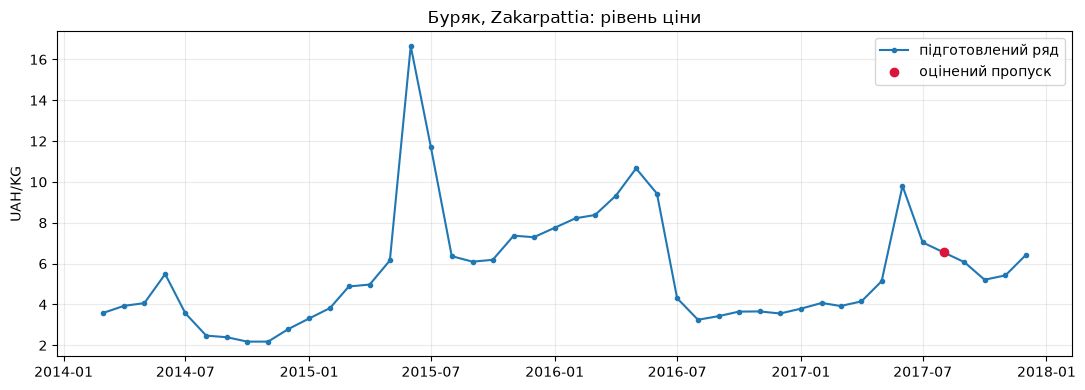

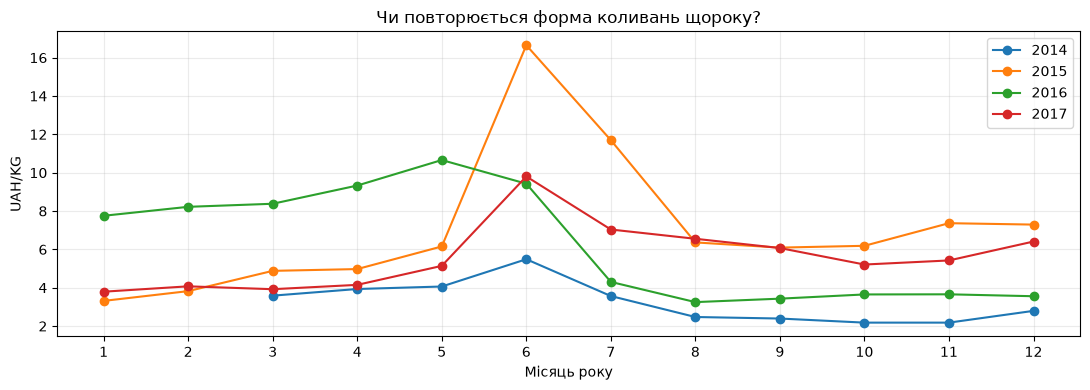

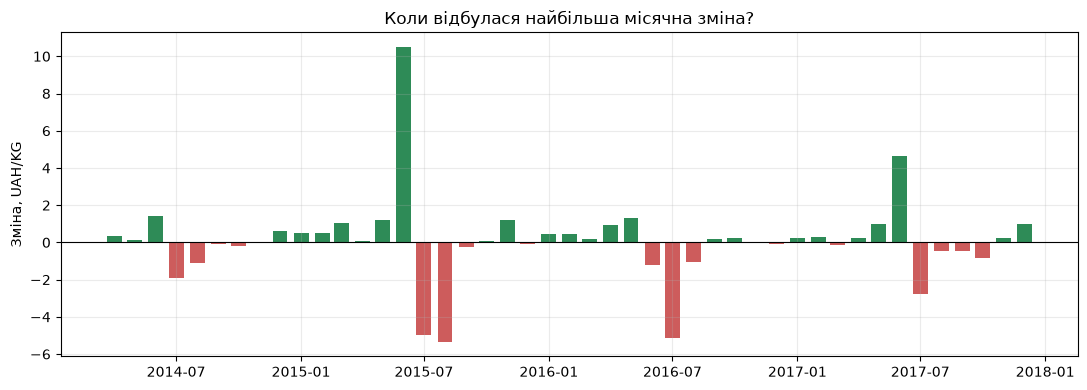

**Висновок.** Лінійний графік зберігає часовий порядок та показує абсолютний рівень; лінійна шкала дає однакову висоту однаковій зміні у гривнях. Сезонні профілі зі спільною шкалою зіставляють однакові місяці різних років; повторювана форма важливіша за відмінність рівнів. Стовпчики перших різниць з нульовою базою показують знак і величину місячної зміни без перебільшення. Помітна знахідка: найбільша абсолютна зміна припала на 06.2015 і становила +10.4967 UAH/KG. Чи була ця знахідка особисто неочікуваною, студент має зазначити сам.

In [5]:
# 1. Рівень і зміна в часі: лінія з рівномірною місячною віссю, лінійна шкала.
fig, ax = plt.subplots()
ax.plot(s.index, s, marker='.', label='підготовлений ряд')
ax.scatter(missing, s.loc[missing], color='crimson', zorder=5, label='оцінений пропуск')
ax.set(title=f'{GOOD_UA.capitalize()}, {MARKET}: рівень ціни', ylabel=f'{currency}/{unit}')
ax.legend(); savefig('03_ряд.png')
# 2. Порівняння однакових місяців різних років без змішування календаря.
season = pd.DataFrame({'price':s, 'year':s.index.year, 'month':s.index.month})
fig, ax = plt.subplots()
for year, part in season.groupby('year'):
    ax.plot(part['month'], part['price'], marker='o', label=str(year))
ax.set(xticks=range(1,13), xlabel='Місяць року', ylabel=f'{currency}/{unit}',
       title='Чи повторюється форма коливань щороку?')
ax.legend(); savefig('03_сезонні_профілі.png')
# 3. Перші різниці: стовпчики зі спільною нульовою базою.
delta = s.diff().dropna()
fig, ax = plt.subplots()
ax.bar(delta.index, delta, width=22, color=np.where(delta >= 0, 'seagreen', 'indianred'))
ax.axhline(0, color='black', lw=0.8)
ax.set(title='Коли відбулася найбільша місячна зміна?', ylabel=f'Зміна, {currency}/{unit}')
savefig('03_місячні_зміни.png')
jump_date = delta.abs().idxmax()
conclusion('Лінійний графік зберігає часовий порядок та показує абсолютний рівень; '
           'лінійна шкала дає однакову висоту однаковій зміні у гривнях. '
           'Сезонні профілі зі спільною шкалою зіставляють однакові місяці різних років; '
           'повторювана форма важливіша за відмінність рівнів. Стовпчики перших різниць '
           'з нульовою базою показують знак і величину місячної зміни без перебільшення. '
           f'Помітна знахідка: найбільша абсолютна зміна припала на {jump_date:%m.%Y} '
           f'і становила {delta.loc[jump_date]:+.4f} {currency}/{unit}. '
           'Чи була ця знахідка особисто неочікуваною, студент має зазначити сам.')

**Висновок до завдання 3:** письмове пояснення з фактичними числами формується кодом вище та зберігається у виводі клітинки. Це дає змогу перерахувати його разом із даними без ручного перенесення чисел.

## Завдання 4. Розкладання на складові

Розкладіть ряд на тренд, сезонну складову та залишок методом STL із періодом 12.

**У звіті наведіть:**
1. чотирипанельний графік розкладання;
2. числові значення сили сезонності $F_S$ та сили тренду $F_T$;
3. **висновок: чи є у вашому ряді сезонність**, із посиланням на порогове значення.

> 💡 **Підказка.** STL поверне сезонну складову завжди. Ваше завдання — вирішити, чи вона означає щось, а не чи вона є.

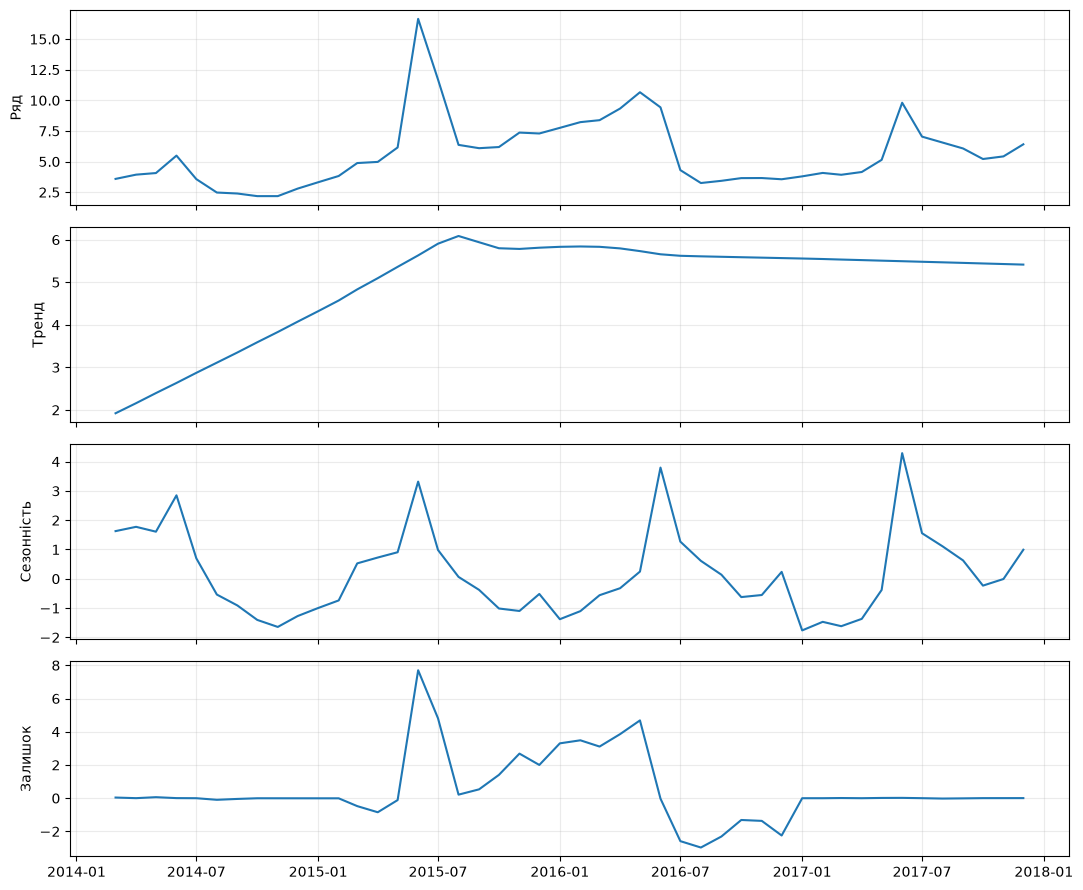

,F_S,F_T,поріг F_S
0,0.364353,0.361716,0.300000


**Висновок.** F_S = 0.3644, F_T = 0.3617. За порогом 0.3 із методички є ознаки сезонності. Формула: max(0, 1 − Var(R)/Var(S+R)); для сили тренду S замінено на T. Сам факт повернення сезонної складової алгоритмом STL не доводить сезонності. Це описова оцінка за менш ніж чотирма річними циклами, а не статистичний тест існування сезонності.

In [6]:
stl = STL(s, period=12, robust=True).fit()
fig, axes = plt.subplots(4, 1, figsize=(11, 9), sharex=True)
for ax, values, label in zip(axes, [s,stl.trend,stl.seasonal,stl.resid],
                           ['Ряд','Тренд','Сезонність','Залишок']):
    ax.plot(values.index, values); ax.set_ylabel(label)
savefig('04_STL.png')
def strength(component, resid):
    denominator = np.var(component + resid, ddof=1)
    return max(0.0, 1 - np.var(resid, ddof=1)/denominator) if denominator else 0.0
FS = strength(stl.seasonal, stl.resid)
FT = strength(stl.trend, stl.resid)
display(pd.DataFrame({'F_S':[FS], 'F_T':[FT], 'поріг F_S':[0.3]}))
seasonal_claim = 'є ознаки сезонності' if FS >= .3 else 'переконливих ознак сезонності немає'
conclusion(f'F_S = {FS:.4f}, F_T = {FT:.4f}. За порогом 0.3 із методички '
           f'{seasonal_claim}. Формула: max(0, 1 − Var(R)/Var(S+R)); '
           'для сили тренду S замінено на T. Сам факт повернення сезонної складової '
           'алгоритмом STL не доводить сезонності. Це описова оцінка за менш ніж '
           'чотирма річними циклами, а не статистичний тест існування сезонності.')

**Висновок до завдання 4:** письмове пояснення з фактичними числами формується кодом вище та зберігається у виводі клітинки. Це дає змогу перерахувати його разом із даними без ручного перенесення чисел.

## Завдання 5. Стаціонарність

Побудуйте ACF і PACF вихідного ряду та його першої різниці. Застосуйте тести ADF і KPSS до обох.

**У звіті наведіть:**
1. графіки ACF і PACF до та після диференціювання;
2. таблицю з $p$-значеннями обох тестів для обох рядів;
3. висновок про стаціонарність **із зазначенням, узгоджуються тести між собою чи ні**;
4. якщо не узгоджуються — ваше пояснення, чому.

> 💡 **Підказка.** Нульові гіпотези ADF і KPSS протилежні. Перш ніж писати висновок, перевірте, що ви не переплутали напрямок.

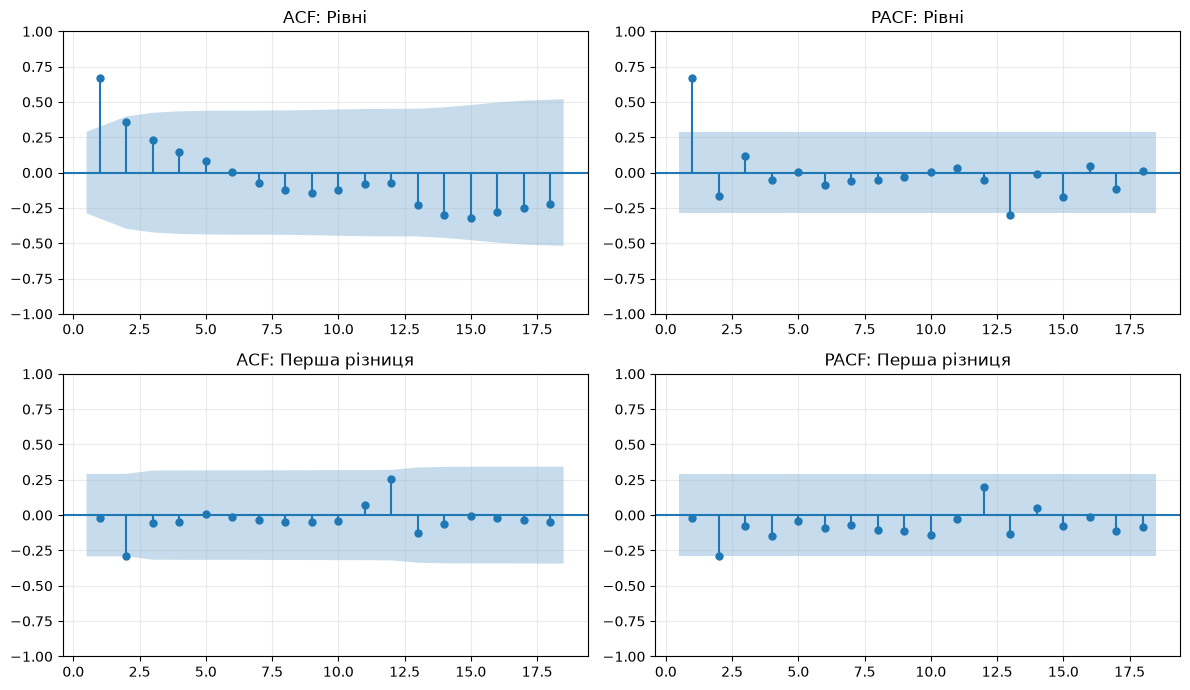

,ADF p,KPSS p,ADF лагів,KPSS лагів,примітка
ряд,,,,,
Рівні,0.040621,0.100000,0,3,adfuller currently returns a plain tuple whose...
Перша різниця,0.000000,0.100000,1,8,adfuller currently returns a plain tuple whose...


**Висновок.** Рівні: ADF p=0.04062, KPSS p=0.10000; тести узгоджуються на користь стаціонарності.

**Висновок.** Перша різниця: ADF p=0.00000, KPSS p=0.10000; тести узгоджуються на користь стаціонарності.

**Висновок.** H₀ ADF — одиничний корінь, H₀ KPSS — стаціонарність відносно константи. Невідхилення H₀ не є її доведенням. Значення KPSS 0.01 або 0.10 можуть бути межами таблиці, а не точним p; див. примітки. Усі тести виконано з константою, без детермінованого лінійного тренду.

In [7]:
diff = s.diff().dropna()
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for row, (label,x) in enumerate([('Рівні',s),('Перша різниця',diff)]):
    plot_acf(x, lags=18, alpha=.05, zero=False, ax=axes[row,0], title=f'ACF: {label}')
    plot_pacf(x, lags=18, alpha=.05, zero=False, method='ywm', ax=axes[row,1], title=f'PACF: {label}')
savefig('05_ACF_PACF.png')
test_rows=[]
for label,x in [('Рівні',s),('Перша різниця',diff)]:
    # Попередження KPSS містять інформацію про межі табличних p, тому зберігаємо їх.
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        adf = adfuller(x, regression='c', autolag='AIC')
        kp = kpss(x, regression='c', nlags='auto')
    test_rows.append({'ряд':label,'ADF p':adf[1], 'KPSS p':kp[1],
                      'ADF лагів':adf[2], 'KPSS лагів':kp[2],
                      'примітка':'; '.join(str(w.message) for w in caught)})
tests = pd.DataFrame(test_rows).set_index('ряд'); display(tests)
for label,row in tests.iterrows():
    a, k = row['ADF p'] < .05, row['KPSS p'] < .05
    if a and not k:
        verdict='тести узгоджуються на користь стаціонарності'
    elif not a and k:
        verdict='тести узгоджуються на користь нестаціонарності'
    else:
        verdict=('тести не дають узгодженого висновку; можлива мала потужність на короткому '
                 'ряді, тренд або зсув рівня. Не можна обирати лише зручний тест')
    conclusion(f'{label}: ADF p={row["ADF p"]:.5f}, KPSS p={row["KPSS p"]:.5f}; {verdict}.')
conclusion('H₀ ADF — одиничний корінь, H₀ KPSS — стаціонарність відносно константи. '
           'Невідхилення H₀ не є її доведенням. Значення KPSS 0.01 або 0.10 можуть '
           'бути межами таблиці, а не точним p; див. примітки. Усі тести виконано '
           'з константою, без детермінованого лінійного тренду.')

**Висновок до завдання 5:** письмове пояснення з фактичними числами формується кодом вище та зберігається у виводі клітинки. Це дає змогу перерахувати його разом із даними без ручного перенесення чисел.

## Завдання 6. Базисні прогнози та ретроспективна перевірка

Побудуйте **чотири** базисні прогнози: наївний, сезонний наївний, середнє та дрейф.
Оцініть їх **ретроспективною перевіркою з рухомим початком**: **7 фолдів по 3 кроки**,
навчальна частина розширюється.

**У звіті наведіть:**
1. таблицю MAE, RMSE і MAPE для всіх чотирьох базисів;
2. який базис виявився найкращим і **чому саме він** — поясніть через властивості вашого ряду;
3. для порівняння: ту саму оцінку, зроблену звичайним випадковим поділом 75/25, і **у скільки разів** вона відрізняється.

> 💡 **Підказка.** Кількість фолдів і кроків задана жорстко — у Частині 2 вона має збігтися з налаштуваннями Orange.

In [8]:
FOLDS, H = 7, 3
# Orange перебирає фолди з кінця. У хронологічному порядку train розширюється.
splits=[]
for f in range(1,FOLDS+1):
    end = len(s)-f*H
    splits.append((f,end,end+H))
fold_table = pd.DataFrame([{'фолд Orange':f, 'навчання від':s.index[0],
    'навчання до':s.index[end-1], 'N train':end,
    'тест від':s.index[end], 'тест до':s.index[stop-1]} for f,end,stop in splits])
display(fold_table)

def metric(y,p):
    y,p=np.asarray(y,float),np.asarray(p,float)
    assert y.shape==p.shape and np.isfinite(p).all() and (y!=0).all()
    e=y-p
    return {'MAE':np.mean(np.abs(e)), 'RMSE':np.sqrt(np.mean(e**2)),
            'MAPE %':100*np.mean(np.abs(e/y))}

def baseline(train, dates, name):
    # Календар збережено також у навмисно неправильному випадковому поділі.
    if name=='Наївний': return np.repeat(train.iloc[-1],len(dates))
    if name=='Середнє': return np.repeat(train.mean(),len(dates))
    if name=='Дрейф':
        age=(train.index[-1].year-train.index[0].year)*12+train.index[-1].month-train.index[0].month
        steps=np.array([(d.year-train.index[-1].year)*12+d.month-train.index[-1].month for d in dates])
        return train.iloc[-1]+steps*(train.iloc[-1]-train.iloc[0])/age
    if name=='Сезонний наївний':
        # Для нормальних фолдів це рівно y[t-12]. Для random іноді бракує
        # цього місяця: відступаємо цілими роками в доступному train.
        values=[]
        for d in dates:
            prior=d-pd.DateOffset(years=1)
            while prior not in train.index and prior >= train.index[0]:
                prior-=pd.DateOffset(years=1)
            if prior in train.index: values.append(train.loc[prior])
            else:
                same=train[(train.index.month==d.month)&(train.index<d)]
                values.append(same.iloc[-1] if len(same) else train.mean())
        return np.asarray(values)
    raise ValueError(name)

names=['Наївний','Сезонний наївний','Середнє','Дрейф']
records=[]
for f,end,stop in splits:
    train,test=s.iloc[:end],s.iloc[end:stop]
    # Жоден train не заповнює серпень за невідомим йому вереснем.
    assert not (missing[0] in train.index and pd.Timestamp('2017-09-01') not in train.index)
    for name in names:
        pred=baseline(train,test.index,name)
        for date,y,p in zip(test.index,test,pred):
            records.append({'model':name,'fold':f,'date':date,'true':y,'pred':p,
                            'imputed':date in missing})
base_predictions=pd.DataFrame(records)
base_scores=pd.DataFrame({n:metric(g['true'],g['pred']) for n,g in base_predictions.groupby('model')}).T
display(base_scores.sort_values('RMSE'))
# Для RMSE середнє коренів по фолдах не дорівнює кореню об'єднаного MSE.
fold_scores=pd.DataFrame([{'model':n,'fold':f,**metric(g['true'],g['pred'])}
    for (n,f),g in base_predictions.groupby(['model','fold'])])
display(fold_scores.groupby('model')[['MAE','RMSE','MAPE %']].mean().rename(columns={'RMSE':'середнє RMSE фолдів'}))
best_base=base_scores['RMSE'].idxmin()

# Вимога про random 75/25: демонстрація непридатної для прогнозу перевірки.
tr_idx,te_idx=train_test_split(np.arange(len(s)),test_size=.25,random_state=42)
random_train=s.iloc[np.sort(tr_idx)]; random_test=s.iloc[np.sort(te_idx)]
random_scores=pd.DataFrame({n:metric(random_test,baseline(random_train,random_test.index,n)) for n in names}).T
comparison=random_scores.add_suffix(' random').join(base_scores.add_suffix(' rolling'))
for col in ['MAE','RMSE','MAPE %']:
    comparison[col+' random/rolling']=random_scores[col]/base_scores[col]
display(comparison)
base_predictions.to_csv(OUT/'прогнози_базисів.csv',index=False)
fold_table.to_csv(OUT/'фолди.csv',index=False,date_format='%Y-%m-%d')
conclusion(f'Критерій вибору заздалегідь — мінімальний об’єднаний RMSE. '
           f'Найкращий базис: «{best_base}», RMSE={base_scores.loc[best_base,"RMSE"]:.4f}. '
           'Сезонний базис використовує ціну того самого місяця попереднього року, '
           'дрейф — середню зміну від початку train, наївний — останній рівень, '
           'середнє — весь історичний рівень. Результат показує, яка з цих властивостей '
           'краще переноситься на останні 21 місяць; сильна сезонність STL сама собою '
           'не гарантує перемоги сезонного базису за зміни рівня. '
           f'Для переможця RMSE random/rolling = {comparison.loc[best_base,"RMSE random/rolling"]:.3f}. '
           'Відношення нижче 1 означає заниження похибки; вище 1 — завищення. '
           'Випадковий поділ тут навмисно хибний: train містить майбутнє відносно '
           'деяких тестових дат, а частина дат фактично перевіряє ретрополяцію. '
           'Це не доказ універсального коефіцієнта оптимізму. Дати й ціни не '
           'перемішано, y_test не відсортовано за величиною. Метрики об’єднані '
           'по 21 прогнозу для точного зіставлення з Orange; окремо наведено '
           'середні метрики фолдів, як описано у теоретичній частині методички.')

,фолд Orange,навчання від,навчання до,N train,тест від,тест до
0,1,2014-03-01,2017-09-01,43,2017-10-01,2017-12-01
1,2,2014-03-01,2017-06-01,40,2017-07-01,2017-09-01
2,3,2014-03-01,2017-03-01,37,2017-04-01,2017-06-01
3,4,2014-03-01,2016-12-01,34,2017-01-01,2017-03-01
4,5,2014-03-01,2016-09-01,31,2016-10-01,2016-12-01
5,6,2014-03-01,2016-06-01,28,2016-07-01,2016-09-01
6,7,2014-03-01,2016-03-01,25,2016-04-01,2016-06-01


,MAE,RMSE,MAPE %
Середнє,2.006303,2.388983,38.449919
Наївний,2.008888,2.908642,40.187156
Дрейф,2.058247,3.066453,42.125227
Сезонний наївний,3.701745,4.060900,75.356283


,MAE,середнє RMSE фолдів,MAPE %
model,,,
Дрейф,2.058247,2.254013,42.125227
Наївний,2.008888,2.187742,40.187156
Сезонний наївний,3.701745,3.912675,75.356283
Середнє,2.006303,2.119920,38.449919


,MAE random,RMSE random,MAPE % random,MAE rolling,RMSE rolling,MAPE % rolling,MAE random/rolling,RMSE random/rolling,MAPE % random/rolling
Наївний,2.461946,2.794982,58.066773,2.008888,2.908642,40.187156,1.225527,0.960923,1.444909
Сезонний наївний,2.752096,3.164634,58.456896,3.701745,4.060900,75.356283,0.743459,0.779294,0.775740
Середнє,2.314804,2.823972,47.773728,2.006303,2.388983,38.449919,1.153766,1.182081,1.242492
Дрейф,2.141944,2.667671,36.792783,2.058247,3.066453,42.125227,1.040664,0.869953,0.873414


**Висновок.** Критерій вибору заздалегідь — мінімальний об’єднаний RMSE. Найкращий базис: «Середнє», RMSE=2.3890. Сезонний базис використовує ціну того самого місяця попереднього року, дрейф — середню зміну від початку train, наївний — останній рівень, середнє — весь історичний рівень. Результат показує, яка з цих властивостей краще переноситься на останні 21 місяць; сильна сезонність STL сама собою не гарантує перемоги сезонного базису за зміни рівня. Для переможця RMSE random/rolling = 1.182. Відношення нижче 1 означає заниження похибки; вище 1 — завищення. Випадковий поділ тут навмисно хибний: train містить майбутнє відносно деяких тестових дат, а частина дат фактично перевіряє ретрополяцію. Це не доказ універсального коефіцієнта оптимізму. Дати й ціни не перемішано, y_test не відсортовано за величиною. Метрики об’єднані по 21 прогнозу для точного зіставлення з Orange; окремо наведено середні метрики фолдів, як описано у теоретичній частині методички.

**Висновок до завдання 6:** письмове пояснення з фактичними числами формується кодом вище та зберігається у виводі клітинки. Це дає змогу перерахувати його разом із даними без ручного перенесення чисел.

## Завдання 7. Модель ARIMA

Побудуйте модель ARIMA і оцініть її **на тих самих 7 фолдах по 3 кроки**.

Обов'язково використайте порядок **(1, 1, 1)** — саме його ви відтворюватимете в Orange.
Додатково визначте, який порядок $(p, d, q)$ ви обрали б **за виглядом ACF і PACF** із завдання 5.

**У звіті наведіть:**
1. MAE, RMSE і MAPE моделі ARIMA(1,1,1) на рухомому початку;
2. обґрунтування порядку, який ви обрали б самостійно, з посиланням на конкретні лаги;
3. **порівняння з найкращим базисом із завдання 6** — і прямий висновок, чи має ця модель право на існування;
4. графік залишків моделі та висновок, чи лишилася в них структура.

> 💡 **Підказка.** Якщо ARIMA програла базису — це законний результат, а не помилка. Напишіть про це прямо.

,MAE,RMSE,MAPE %
"ARIMA(1,1,1)",2.112359,2.840572,41.566458
Найкращий базис: Середнє,2.006303,2.388983,38.449919


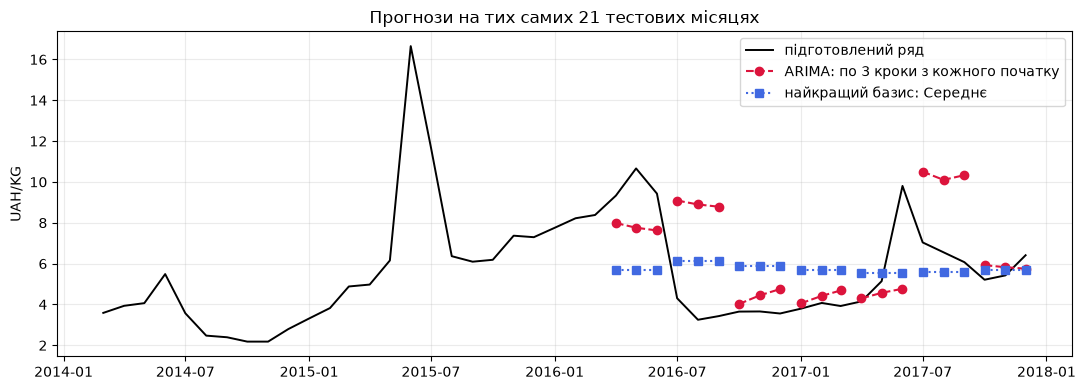

**Висновок.** Червоні й сині відрізки — справжні тримісячні прогнози без доступу до майбутніх значень свого фолду. На графіку видно, що реакція ARIMA на останні рухи не забезпечує переваги над історичним середнім; остаточний висновок ґрунтується на таблиці похибок, а не лише на вигляді ліній.

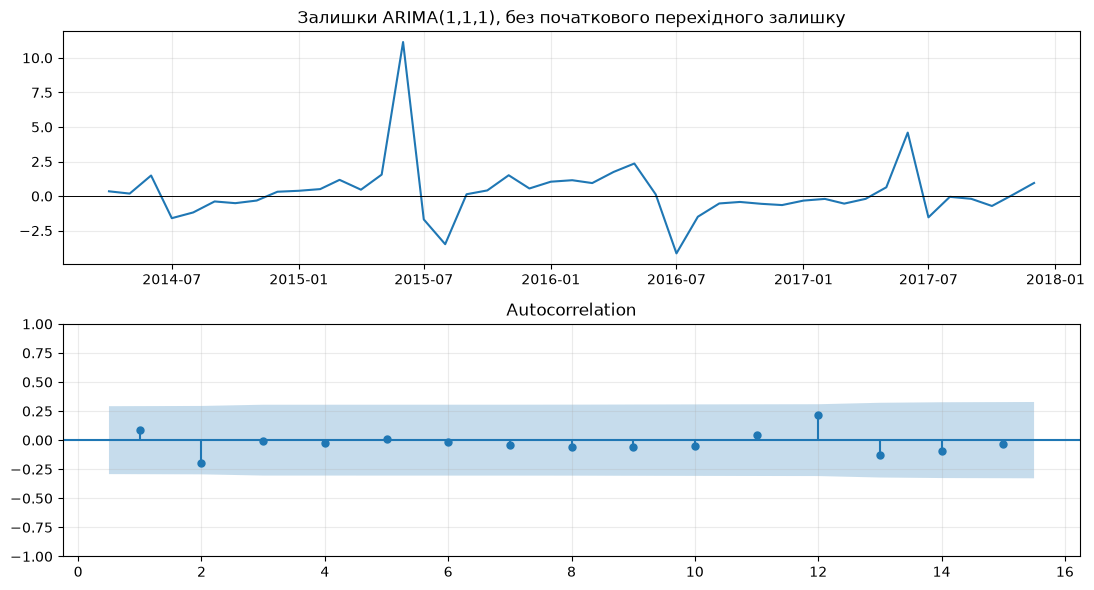

,lb_stat,lb_pvalue
6,2.216210,0.696063
12,6.007562,0.814627


C:\Users\Olexandr\AppData\Local\Temp\ipykernel_21084\96275251.py:43: FutureWarning: acf currently returns a plain tuple whose length depends on the qstat and alpha arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an AcfResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  ac_vals,ac_ci=acf(identify,nlags=12,alpha=.05)


,лаг,ACF,PACF,ACF значущий,PACF значущий
0,1,0.668965,0.668965,True,True
1,2,0.355921,-0.165784,False,False
2,3,0.230910,0.119565,False,False
3,4,0.146411,-0.049161,False,False
4,5,0.080825,0.003734,False,False
5,6,0.001466,-0.084480,False,False
6,7,-0.075907,-0.060603,False,False
7,8,-0.124731,-0.052040,False,False
8,9,-0.142427,-0.028364,False,False
9,10,-0.125483,0.007425,False,False


**Висновок.** ARIMA RMSE=2.8406, найкращий базис RMSE=2.3890: модель не перевершила базис. Практичної переваги за вибраним критерієм не продемонстровано; простіший базис доцільніший. Самостійно обрано d=0 за тестами; таблиця ACF/PACF вище стосується цього ряду. Кандидат (1, 0, 0): PACF має один виразний лаг 1, тоді як ACF не має переконливого обриву. Значущі ACF-лаги: [1]; PACF-лаги: [1]. Це евристика за коротким рядом, не доведений оптимальний порядок. Ljung–Box на лагах 6 і 12 дає p=0.6961 та 0.8146; залишкової автокореляції цими тестами не виявлено, проте білий шум не доведено.

,MAE,RMSE,MAPE %
"46-точкова сітка, 21 прогноз",2.112359,2.840572,41.566458
лише 20 виміряних тестових точок,2.040603,2.800547,40.938173


**Висновок.** Основна оцінка відповідає вимозі однакових 46 точок для Python та Orange. Окремий рядок чутливості вилучає з оцінювання серпень 2017, який було інтерпольовано: основна оцінка частково порівнює прогноз з оцінкою, а не з виміром.

In [9]:
arima_records=[]; fit_warnings=[]
for f,end,stop in splits:
    # ndarray і стандартні налаштування — як у обгортці Orange.
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        fit=ARIMA(s.iloc[:end].to_numpy(),order=(1,1,1),missing='raise').fit()
    fit_warnings.extend({'fold':f,'warning':str(w.message)} for w in caught)
    for date,y,p in zip(s.index[end:stop],s.iloc[end:stop],fit.forecast(H)):
        arima_records.append({'fold':f,'date':date,'true':y,'pred':p,'imputed':date in missing})
arima_predictions=pd.DataFrame(arima_records)
arima_scores=metric(arima_predictions['true'],arima_predictions['pred'])
display(pd.DataFrame({'ARIMA(1,1,1)':arima_scores,'Найкращий базис: '+best_base:base_scores.loc[best_base]}).T)
if fit_warnings: display(pd.DataFrame(fit_warnings))

# Показуємо саме перевірені прогнози; окремі відрізки не з'єднуємо через межі фолдів.
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(s.index,s,color='black',lw=1.4,label='підготовлений ряд')
for number,(f,part) in enumerate(arima_predictions.groupby('fold')):
    ax.plot(part['date'],part['pred'],'o--',color='crimson',
            label='ARIMA: по 3 кроки з кожного початку' if number==0 else None)
    base_part=base_predictions[(base_predictions['model']==best_base)&(base_predictions['fold']==f)]
    ax.plot(base_part['date'],base_part['pred'],'s:',color='royalblue',
            label='найкращий базис: '+best_base if number==0 else None)
ax.set(ylabel=f'{currency}/{unit}',title='Прогнози на тих самих 21 тестових місяцях')
ax.legend(); savefig('07_прогнози_на_тесті.png')
conclusion('Червоні й сині відрізки — справжні тримісячні прогнози без доступу '
           'до майбутніх значень свого фолду. На графіку видно, що реакція '
           'ARIMA на останні рухи не забезпечує переваги над історичним середнім; '
           'остаточний висновок ґрунтується на таблиці похибок, а не лише на вигляді ліній.')
full_fit=ARIMA(s.to_numpy(),order=(1,1,1),missing='raise').fit()

# Перший залишок при d=1 залежить від ініціалізації фільтра; його вилучено.
burn=max(1,full_fit.loglikelihood_burn)
resid=pd.Series(np.asarray(full_fit.resid)[burn:],index=s.index[burn:])
fig,axes=plt.subplots(2,1,figsize=(11,6))
axes[0].plot(resid.index,resid); axes[0].axhline(0,color='black',lw=.7)
axes[0].set_title('Залишки ARIMA(1,1,1), без початкового перехідного залишку')
plot_acf(resid,lags=15,zero=False,ax=axes[1]); savefig('07_залишки_ARIMA.png')
lb=acorr_ljungbox(resid,lags=[6,12],model_df=2,return_df=True); display(lb)
# Самостійний кандидат не зобов'язаний мати d=1, заданий для порівняння.
d_choice=0 if tests.loc['Рівні','ADF p']<.05 and tests.loc['Рівні','KPSS p']>=.05 else 1
identify=s if d_choice==0 else diff
ac_vals,ac_ci=acf(identify,nlags=12,alpha=.05)
pc_vals,pc_ci=pacf(identify,nlags=12,alpha=.05,method='ywm')
lag_table=pd.DataFrame({'лаг':np.arange(1,13),'ACF':ac_vals[1:],'PACF':pc_vals[1:],
    'ACF значущий':(ac_ci[1:,0]>0)|(ac_ci[1:,1]<0),
    'PACF значущий':(pc_ci[1:,0]>0)|(pc_ci[1:,1]<0)})
display(lag_table)
sig_ac=lag_table.loc[lag_table['ACF значущий'],'лаг'].tolist()
sig_pc=lag_table.loc[lag_table['PACF значущий'],'лаг'].tolist()
if sig_pc==[1]: candidate=(1,d_choice,0); reason='PACF має один виразний лаг 1, тоді як ACF не має переконливого обриву'
elif sig_ac==[1]: candidate=(0,d_choice,1); reason='ACF має один виразний лаг 1, а PACF не має переконливого обриву'
elif not sig_ac and not sig_pc: candidate=(0,d_choice,0); reason='в обраному для ідентифікації ряді немає значущих лагів 1–12'
else: candidate=(1,d_choice,1); reason='немає чистого обриву лише однієї функції; змішаний малий порядок є кандидатом'
win=arima_scores['RMSE'] < base_scores.loc[best_base,'RMSE']
conclusion(f'ARIMA RMSE={arima_scores["RMSE"]:.4f}, найкращий базис RMSE='
           f'{base_scores.loc[best_base,"RMSE"]:.4f}: модель '+('перевершила' if win else 'не перевершила')+
           ' базис. '+('На цьому backtest є аргумент на її користь.' if win else
           'Практичної переваги за вибраним критерієм не продемонстровано; простіший базис доцільніший.')+
           f' Самостійно обрано d={d_choice} за тестами; таблиця ACF/PACF вище стосується цього ряду. Кандидат {candidate}: {reason}. Значущі ACF-лаги: {sig_ac}; '
           f'PACF-лаги: {sig_pc}. Це евристика за коротким рядом, не доведений оптимальний порядок. '
           f'Ljung–Box на лагах 6 і 12 дає p={lb.iloc[0]["lb_pvalue"]:.4f} та '
           f'{lb.iloc[1]["lb_pvalue"]:.4f}; '+
           ('є свідчення залишкової автокореляції.' if (lb['lb_pvalue']<.05).any() else
           'залишкової автокореляції цими тестами не виявлено, проте білий шум не доведено.'))
arima_predictions.to_csv(OUT/'прогнози_ARIMA.csv',index=False,date_format='%Y-%m-%d')
# Чутливість: оцінений серпень у тесті не є реальним виміром.
observed=arima_predictions.loc[~arima_predictions['imputed']]
display(pd.DataFrame({'46-точкова сітка, 21 прогноз':arima_scores,
    'лише 20 виміряних тестових точок':metric(observed['true'],observed['pred'])}).T)
conclusion('Основна оцінка відповідає вимозі однакових 46 точок для Python та Orange. '
           'Окремий рядок чутливості вилучає з оцінювання серпень 2017, який було '
           'інтерпольовано: основна оцінка частково порівнює прогноз з оцінкою, а не з виміром.')

**Висновок до завдання 7:** письмове пояснення з фактичними числами формується кодом вище та зберігається у виводі клітинки. Це дає змогу перерахувати його разом із даними без ручного перенесення чисел.

## Завдання 8. Точка зміни режиму

Знайдіть у своєму ряді точку, після якої змінюється **рівень** ряду.
Скористайтеся скануванням: для кожної кандидатної дати порівняйте середні до і після
та оберіть дату з найбільшою t-статистикою.

**У звіті наведіть:**
1. графік ряду з позначеною знайденою датою;
2. дату, значення t-статистики, середні рівні до і після;
3. **чи є ця точка значущою** — і якщо ні, так і напишіть;
4. чим знайдена точка відрізняється від звичайного сезонного сплеску у вашому ряді.

> 💡 **Підказка.** Не плутайте зсув рівня з сезонним піком. Якщо «аномалії» повторюються щороку в ті самі місяці — це сезон.

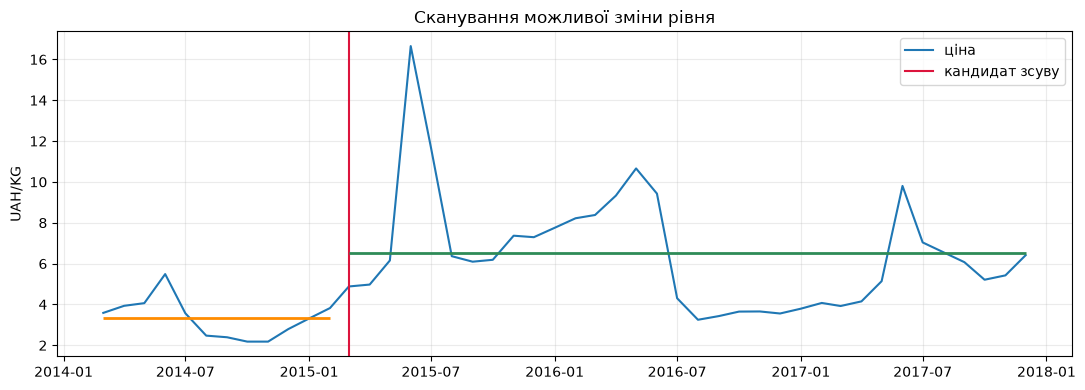

,значення
k,12
дата,2015-03-01 00:00:00
t,-5.623350
|t|,5.623350
p Welch,0.000001
середнє до,3.316100
середнє після,6.495878


**Висновок.** Найбільше |t| у скануванні 23 дат: межа 03.2015, t=-5.6234, середні 3.3161 та 6.4959. Наївне p Welch=1.2036e-06; після поправки Бонферроні p=2.7684e-05. За припущень незалежного Welch це значущий кандидат. Але місячні ціни залежні, ряд має тренд і можливу сезонність, тому статистичну значущість саме структурного зламу цим скануванням не встановлено. Поправка за перебір дат не усуває автокореляції. Сезонний пік повторюється приблизно в тому самому місяці, а зсув рівня означає тривале зміщення; графік і середні лише висувають кандидата. Причинного або зовнішнього пояснення конкретної дати з CSV отримати не можна; його не вигадуємо.

In [10]:
# Не допускаємо надто коротких країв: принаймні 12 місяців з кожного боку.
scan=[]
for k in range(12,len(s)-12+1):
    left,right=s.iloc[:k],s.iloc[k:]
    t,p=stats.ttest_ind(left,right,equal_var=False)
    scan.append({'k':k,'дата':s.index[k], 't':t, '|t|':abs(t),
                 'p Welch':p, 'середнє до':left.mean(), 'середнє після':right.mean()})
scan=pd.DataFrame(scan)
change=scan.loc[scan['|t|'].idxmax()]
p_bonf=min(1.0,change['p Welch']*len(scan))
fig,ax=plt.subplots()
ax.plot(s.index,s,label='ціна'); ax.axvline(change['дата'],color='crimson',label='кандидат зсуву')
k=int(change['k'])
ax.hlines(change['середнє до'],s.index[0],s.index[k-1],color='darkorange',lw=2)
ax.hlines(change['середнє після'],s.index[k],s.index[-1],color='seagreen',lw=2)
ax.set(ylabel=f'{currency}/{unit}',title='Сканування можливої зміни рівня'); ax.legend()
savefig('08_зміна_рівня.png'); display(change.to_frame('значення'))
conclusion(f'Найбільше |t| у скануванні {len(scan)} дат: межа {change["дата"]:%m.%Y}, '
           f't={change["t"]:.4f}, середні {change["середнє до"]:.4f} та '
           f'{change["середнє після"]:.4f}. Наївне p Welch={change["p Welch"]:.5g}; '
           f'після поправки Бонферроні p={p_bonf:.5g}. '
           +('За припущень незалежного Welch це значущий кандидат.' if p_bonf<.05 else
             'Навіть за припущень незалежного Welch значущості після поправки немає.')+
           ' Але місячні ціни залежні, ряд має тренд і можливу сезонність, тому '
           'статистичну значущість саме структурного зламу цим скануванням не встановлено. '
           'Поправка за перебір дат не усуває автокореляції. Сезонний пік повторюється '
           'приблизно в тому самому місяці, а зсув рівня означає тривале зміщення; '
           'графік і середні лише висувають кандидата. Причинного або зовнішнього '
           'пояснення конкретної дати з CSV отримати не можна; його не вигадуємо.')

**Висновок до завдання 8:** письмове пояснення з фактичними числами формується кодом вище та зберігається у виводі клітинки. Це дає змогу перерахувати його разом із даними без ручного перенесення чисел.

## Завдання 9. Рецензія на чужий аналіз

Відкрийте `ЛР4_помилковий_аналіз.ipynb`. Це звіт, зроблений на іншому ряді з того самого набору.
Він виконується без помилок і виглядає переконливо, але містить **методологічні помилки**.

**У звіті наведіть:**
1. перелік знайдених помилок — для кожної вкажіть номер клітинки, суть помилки й **чим вона небезпечна**;
2. для трьох найсерйозніших — як саме їх виправити.

> 💡 **Підказка.** Помилок щонайменше вісім. Шукайте не синтаксис, а порушення принципів роботи з часовими рядами.

In [11]:
# Рецензія виконана через читання джерельного коду; неправильний звіт не запускаємо.
peer=json.loads(Path('ЛР4_помилковий_аналіз.ipynb').read_text(encoding='utf-8'))
print('Переглянуто клітинок:',len(peer['cells']))
print('Номери у рецензії — індекси масиву cells, а не лічильники виконання.')

Переглянуто клітинок: 23
Номери у рецензії — індекси масиву cells, а не лічильники виконання.


**Висновок до завдання 9:**


**Нумерація:** індекси JSON-клітинок із нуля; в дужках позиція з одиниці. Це не `In [n]`, яке залежить від запуску.

| Клітинка | Помилка | Чим небезпечна |
|---|---|---|
| 3 (4) | `s.isna()` без `reindex(grid)` не помічає відсутнього місяця | 45 записів помилково вважаються повними 46 місяцями; змінюється значення лагів |
| 5 (6) | З ціни одного товару робиться висновок про купівельну спроможність | Немає доходів, інфляції та споживчого кошика; твердження не випливає з даних |
| 7 (8) | MAE різних за ціною товарів порівнюється як універсальна складність прогнозування | Абсолютна похибка залежить від масштабу; потрібні відносні/масштабовані метрики |
| 9 (10) | Кореляція рівнів трактується як причинний вплив Львівщини | Спільний тренд/зовнішні чинники можуть дати хибну кореляцію; напрямок впливу не ідентифіковано |
| 11 (12) | STL із `period=12` застосовано до нерегулярної 45-точкової послідовності | 12 позицій не завжди означають 12 календарних місяців |
| 11 (12) | Сезонність оголошена лише тому, що STL повернув S | STL виділить S завжди; потрібна сила сезонності та повторюваність |
| 13 (14) | Невідхилення H₀ ADF інтерпретовано як стаціонарність | H₀ — одиничний корінь; обрано хибний ступінь інтегрування |
| 13 (14) | Друге диференціювання «для надійності», без перевірки першої різниці | Передиференціювання додає шум і штучну від’ємну автокореляцію |
| 15 (16) | Z-поріг застосовано до рівнів без видалення тренду та сезонності | Звичайні сезонні піки або тренд помилково оголошуються аномальними подіями |
| 15 (16) | У тексті поріг 2σ, у коді 1.3σ | Фактичне правило не відповідає опису, кількість «аномалій» довільно збільшується |
| 17 (18) | `train_test_split` випадково ділить часовий ряд | У train потрапляє майбутнє відносно тестових дат; це не оцінка майбутнього прогнозу |
| 17 (18) | Відібрані випадково train-місяці стискаються в суцільний масив | Модель вважає нерівні календарні інтервали однаковими |
| 17 (18) | `np.sort(y_te)` сортує фактичні ціни за величиною | Прогноз і факт втрачають відповідність дат; MAE перестає вимірювати точність прогнозу |
| 17 (18) | ARIMA та сезонний базис оцінюються на різних датах і горизонтах | Метрики непорівнювані, висновок про якість моделі необґрунтований |
| 17 (18) | «Висока точність» без критерію прийнятності й перемоги над наївним базисом | Маленька на око похибка не доводить практичної корисності |
| 19 (20) | Прогнозується ARIMA(2,2,1), хоча перевірялася (1,1,1) | Результат перевірки іншої моделі не підтверджує якість нового прогнозу |
| 19 (20) | 12-місячний прогноз подано без інтервалу й перевірки такого горизонту | Не показано невизначеність, довгострокове зростання оголошено надто впевнено |
| 21 (22) | Стовпчики цін мають обрізану майже до мінімуму вісь Y | Довжини стовпчиків візуально перебільшують відносне зростання |

**Три першочергові виправлення.**

1. Клітинки 3/11: побудувати `date_range(..., freq='MS')`, зробити `reindex`, явно знайти серпень 2017 і заповнити тільки одиничний пропуск. Тоді STL та лаги 12 мають календарний сенс.
2. Клітинка 17: замінити випадковий поділ сімома хронологічними фолдами по три місяці; зберігати `(date, y_true, y_pred)`, не сортувати ціни; порівняти всі базиси й ARIMA на тих самих датах.
3. Клітинка 13: правильно сформулювати H₀ ADF, додати KPSS для рівнів і першої різниці; обирати d за сукупністю тестів і ACF, а не диференціювати двічі автоматично.

Окремо: причинність, купівельну спроможність та «нетипові події» не можна встановлювати без додаткових даних. У нашому аналізі ці висновки не повторюються.

## Завдання 10. Експорт ряду для Orange

Збережіть підготовлений ряд у файл `ряд_для_orange.csv` **рівно у такому вигляді**:

| Стовпець | Тип | Зміст |
|---|---|---|
| `date` | текст у форматі `РРРР-ММ-ДД` | перше число місяця |
| `price` | число | ціна, пропуск уже заповнений |

Один рядок на місяць, 46 рядків плюс заголовок, роздільник — кома, кодування UTF-8.

**У звіті наведіть:**
1. підтвердження, що файл має 46 рядків даних і не містить порожніх значень.

> 💡 **Підказка.** Формат заданий жорстко: Orange має отримати **точно ті самі** дані, що й Python, інакше порівняння в Частині 2 втрачає сенс.

In [12]:
export=pd.DataFrame({'date':s.index.strftime('%Y-%m-%d'),'price':s.to_numpy()})
export.to_csv('ряд_для_orange.csv',index=False,encoding='utf-8',lineterminator='\n')
check=pd.read_csv('ряд_для_orange.csv')
assert check.columns.tolist()==['date','price'] and check.shape==(46,2)
assert not check.isna().any().any()
assert np.allclose(check['price'],s,rtol=0,atol=1e-12)
assert pd.to_datetime(check['date']).tolist()==s.index.tolist()
assert all(d.endswith('-01') for d in check['date'])
display(check.head()); display(check.tail())
conclusion('CSV перечитано з диска: рівно 46 рядків даних і заголовок date,price; '
           'кома, UTF-8, дати YYYY-MM-DD на перше число місяця. Порожніх значень немає, '
           'ціни збігаються з підготовленим рядом до похибки читання float 1e-12.')

,date,price
0,2014-03-01,3.586700
1,2014-04-01,3.933300
2,2014-05-01,4.063300
3,2014-06-01,5.486700
4,2014-07-01,3.566700


,date,price
41,2017-08-01,6.553350
42,2017-09-01,6.070000
43,2017-10-01,5.210000
44,2017-11-01,5.423300
45,2017-12-01,6.410000


**Висновок.** CSV перечитано з диска: рівно 46 рядків даних і заголовок date,price; кома, UTF-8, дати YYYY-MM-DD на перше число місяця. Порожніх значень немає, ціни збігаються з підготовленим рядом до похибки читання float 1e-12.

**Висновок до завдання 10:** письмове пояснення з фактичними числами формується кодом вище та зберігається у виводі клітинки. Це дає змогу перерахувати його разом із даними без ручного перенесення чисел.

---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

*Виконується самостійно.*

Потрібен додаток **Timeseries**: у Orange відкрийте *Options → Add-ons…* і встановіть `Orange3-Timeseries`.

**Головна умова цієї частини:** Orange має отримати **ті самі дані** й **ті самі налаштування перевірки**,
що й Python у Частині 1. Тоді будь-яка розбіжність у числах пояснюється **лише означеннями метрик**,
а не різними даними чи різними моделями. Саме це вам і треба довести.

## Завдання 11. Потік опрацювання даних

Побудуйте в Orange потік:

`File` → `As Timeseries` → `Interpolate` → `Line Chart`

У віджеті **File** завантажте свій `ряд_для_orange.csv`; переконайтеся, що `date` розпізнано
як **time**, а `price` — як **numeric**. У віджеті **As Timeseries** оберіть `date` як часову змінну.

**У звіті наведіть:**
1. знімок екрана з побудованим потоком;
2. знімок `Line Chart` із вашим рядом;
3. підтвердження, що графік у Orange збігається з графіком із завдання 3.

> 💡 **Підказка.** Якщо `date` розпізнано як текст, поверніться до завдання 10 і перевірте формат дати.

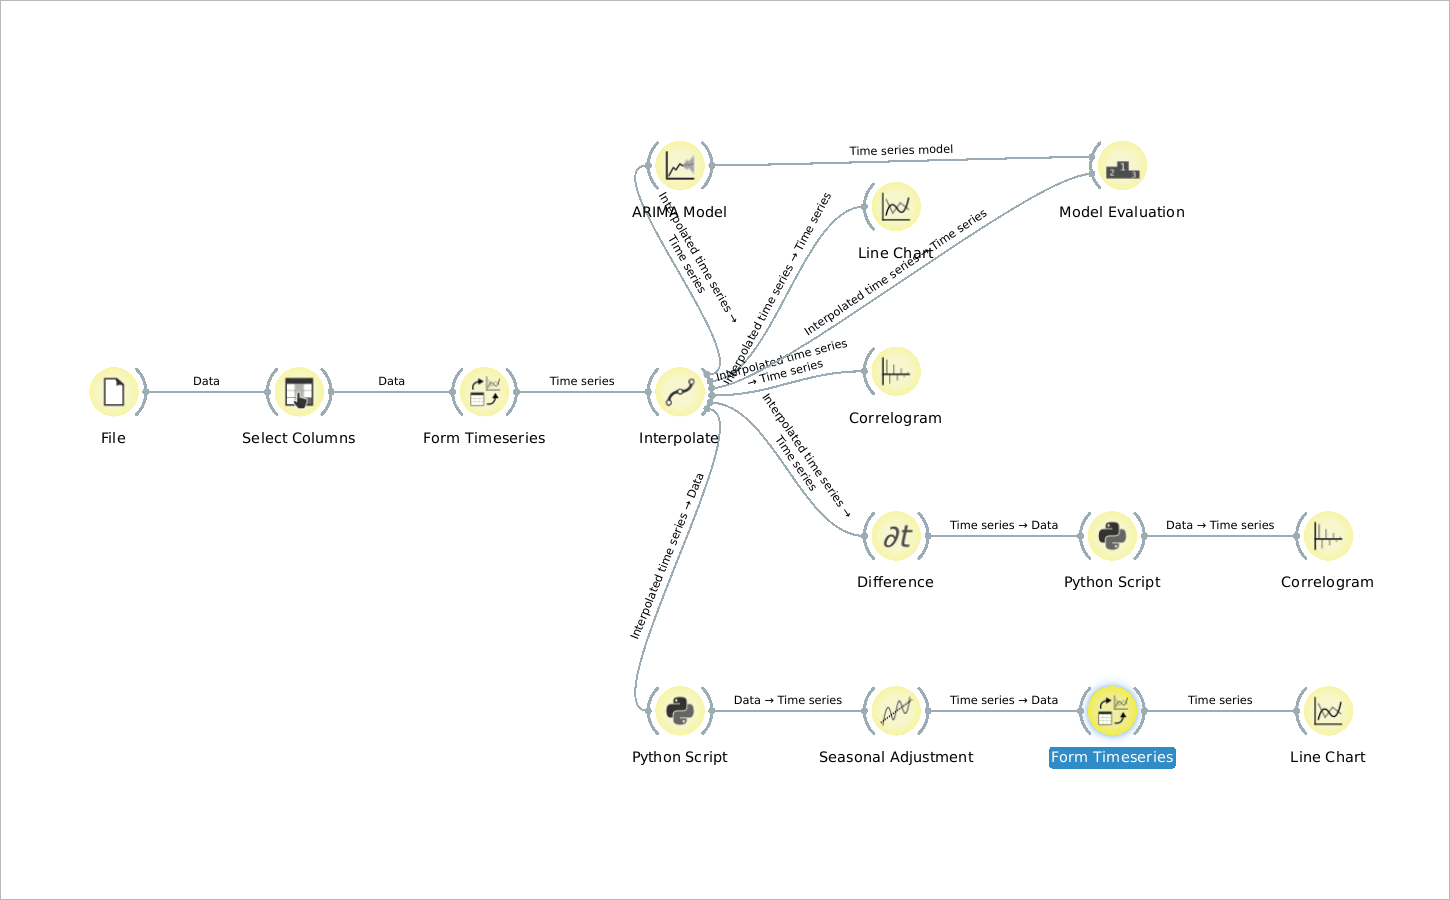

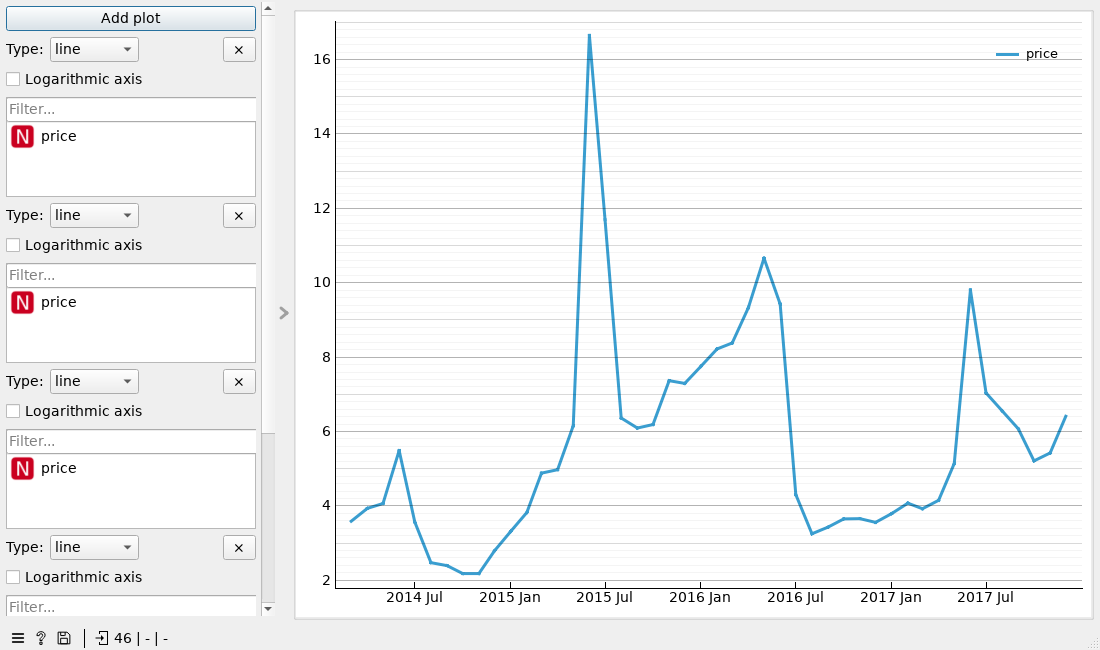

In [13]:
screen_dir=Path('orange_знімки')
for name in ['11_потік.png','11_ряд.png']:
    path=screen_dir/name
    if path.exists(): display(Image(filename=str(path)))
    else: print('Потрібен фактичний знімок Orange:',path)

**Виконано автоматично у справжніх Qt-віджетах Orange, режим offscreen.** Це знімки самих віджетів, а не захоплення робочого столу; студент має відкрити потік і перевірити його особисто.

Збережено `потік_orange.ows`: `File → Select Columns → Form Timeseries → Interpolate → Line Chart`. У Timeseries 0.6.3 віджет із методички **As Timeseries називається Form Timeseries**. Select Columns явно задає price як Target, date як метадані Time. Програмно перевірено всі 46 цін на вході Line Chart: вони збігаються з CSV до 1e-12. Оскільки дані вже повні, Linear Interpolate їх не змінив. Отже графік ціни збігається із завданням 3; знімки потоку, графіка, типів і цілі містяться у `orange_знімки`.

Для власної перевірки відкрити потік через `Відкрити_Orange.cmd`, двічі клацнути Line Chart і звірити форму графіка. Інші ручні дії — в `ІНСТРУКЦІЯ.md`.

## Завдання 12. Автокореляція та диференціювання

Додайте до потоку віджети `Correlogram`, `Difference` та `Seasonal Adjustment`.

**У звіті наведіть:**
1. знімок корелограми;
2. зіставлення з ACF із завдання 5: **чи збігаються висновки** про значущі лаги;
3. знімок сезонно скоригованого ряду та порівняння з сезонною складовою STL із завдання 4.

> 💡 **Підказка.** Orange і statsmodels рахують автокореляцію однаково — якщо картина різна, перевірте, чи однакові дані на вході.

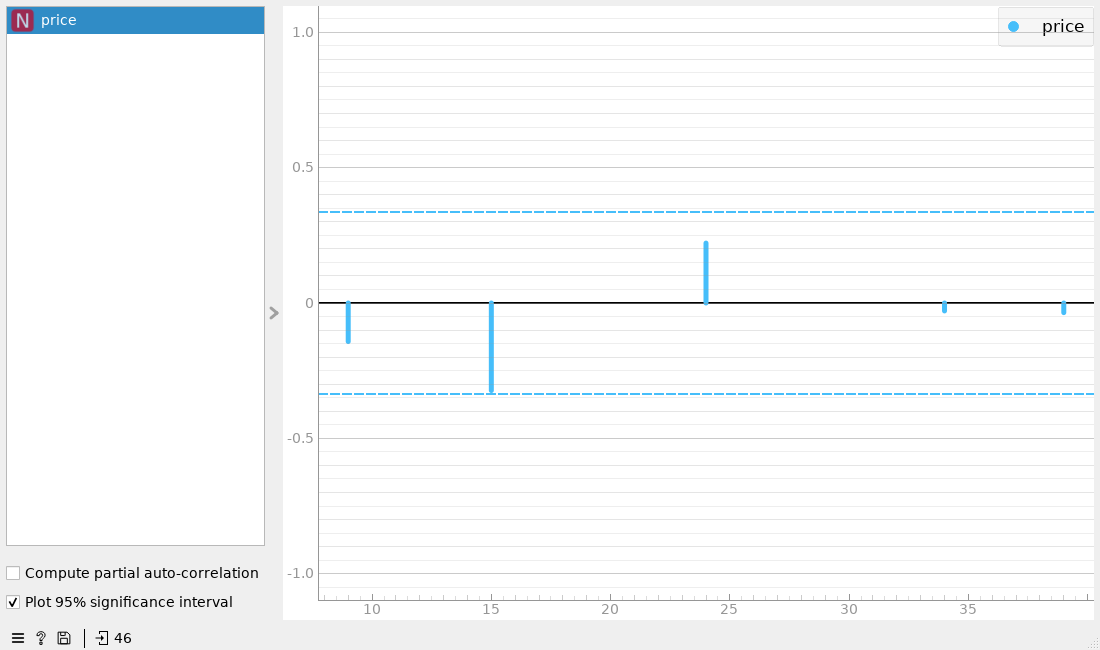

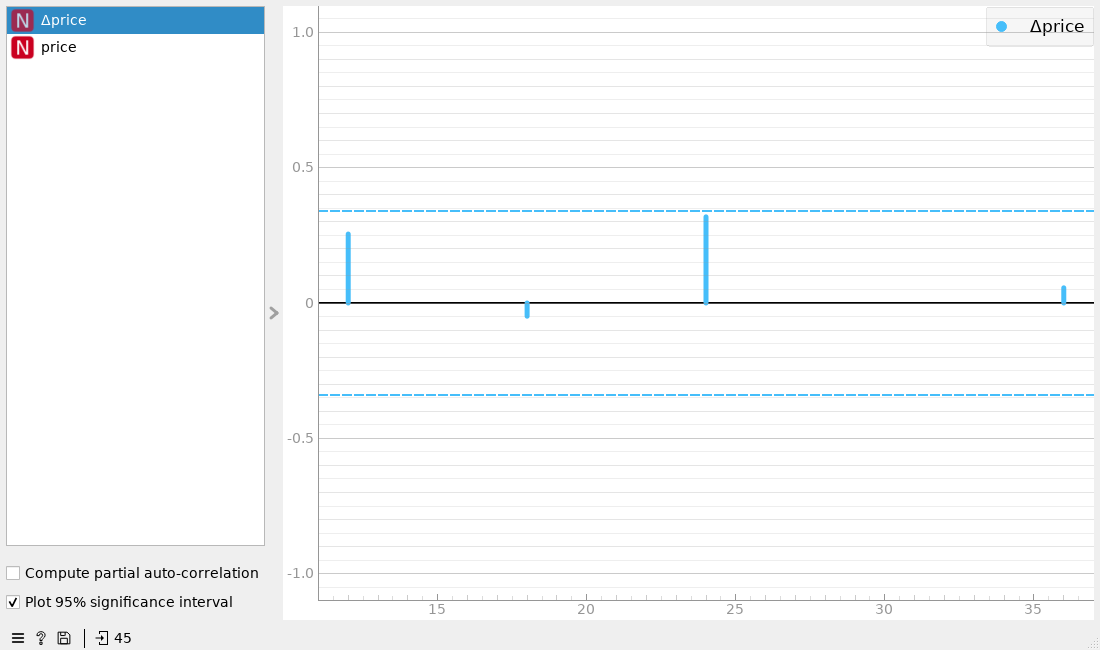

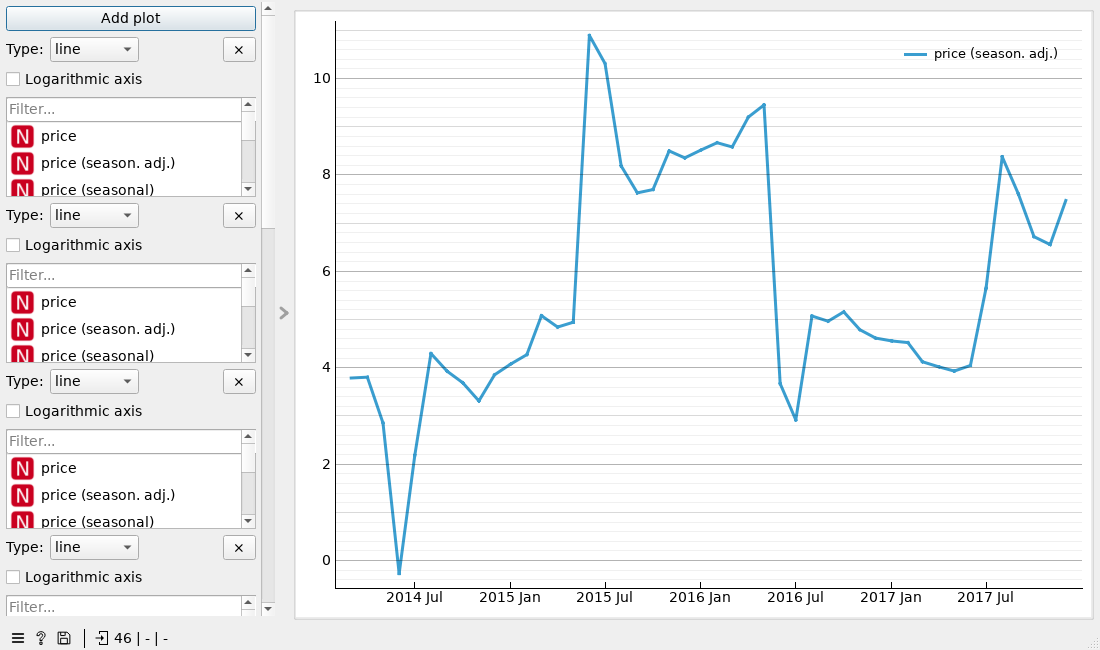

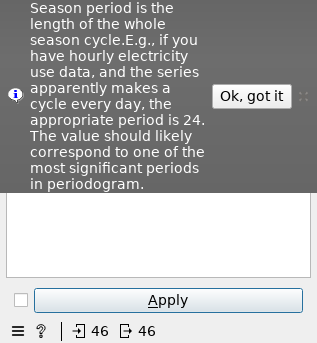

,лаг Orange,ACF,ряд
0,9.000000,-0.142427,рівні
1,15.000000,-0.323356,рівні
2,24.000000,0.221315,рівні
3,34.000000,-0.029335,рівні
4,39.000000,-0.035603,рівні


**Висновок.** рівні: N=46, показані Orange значущі піки []; межа віджета ±0.3360. Коефіцієнти на показаних лагах збігаються зі statsmodels до 1e-12.

,лаг Orange,ACF,ряд
0,12.000000,0.254730,різниця
1,18.000000,-0.048770,різниця
2,24.000000,0.318235,різниця
3,36.000000,0.056032,різниця


**Висновок.** різниця: N=45, показані Orange значущі піки []; межа віджета ±0.3386. Коефіцієнти на показаних лагах збігаються зі statsmodels до 1e-12.

,date,price,Orange seasonal,Orange adjusted,STL seasonal
0,2014-03-01,3.586700,-0.201424,3.788124,1.627438
1,2014-04-01,3.933300,0.128761,3.804539,1.773905
2,2014-05-01,4.063300,1.208298,2.855002,1.607773
3,2014-06-01,5.486700,5.755254,-0.268554,2.849346
4,2014-07-01,3.566700,1.384511,2.182189,0.697250


**Висновок.** Кореляція сезонних складових класичного розкладання Orange та STL = 0.7706. Orange віднімає повторюваний сезонний профіль, STL допускає локальну зміну складових і стійко обробляє викиди. На скоригованому графіку лишаються великі зміни рівня: сезонне коригування не видаляє тренд і всі нетипові рухи.

In [14]:
for name in ['12_корелограма.png','12_корелограма_різниці.png',
             '12_сезонне_коригування.png','12_налаштування_сезонності.png']:
    path=Path('orange_знімки')/name
    if path.exists(): display(Image(filename=str(path)))
    else: print('Немає знімка:',path)
proof_path=OUT/'orange_перевірка.json'
if proof_path.exists():
    proof=json.loads(proof_path.read_text(encoding='utf-8'))
    for label,check in proof['acf_checks'].items():
        display(pd.DataFrame(check['peaks'],columns=['лаг Orange','ACF']).assign(ряд=label))
        conclusion(f'{label}: N={check["n"]}, показані Orange значущі піки '
                   f'{check["significant_peak_lags"]}; межа віджета ±{check["widget_confidence_bound"]:.4f}. '
                   'Коефіцієнти на показаних лагах збігаються зі statsmodels до 1e-12.')
season_path=OUT/'orange_сезонні_складові.csv'
if season_path.exists():
    orange_season=pd.read_csv(season_path)
    display(orange_season.head())
    seasonal_corr=orange_season['Orange seasonal'].corr(orange_season['STL seasonal'])
    conclusion(f'Кореляція сезонних складових класичного розкладання Orange та STL = '
               f'{seasonal_corr:.4f}. Orange віднімає повторюваний сезонний профіль, '
               'STL допускає локальну зміну складових і стійко обробляє викиди. '
               'На скоригованому графіку лишаються великі зміни рівня: '
               'сезонне коригування не видаляє тренд і всі нетипові рухи.')

**Виконано, із задокументованим обходом помилки додатка.**

Correlogram використовує коефіцієнти statsmodels, але показує **лише локальні екстремуми абсолютної ACF**, а не всі лаги. Його горизонтальні 95% межі розраховуються з показаних піків; у `plot_acf` використано лагозалежні межі Bartlett. Тому картинка та виділені значущі лаги не зобов’язані бути однаковими навіть за ідентичних даних. Числовий збіг ACF на показаних лагах перевірено у реальному потоці. Висновки про значущі лаги на рівнях **не збігаються повністю**: Python показує значущий лаг 1 (ACF≈0.669), але Orange не показує його, бо він не є локальним максимумом поруч із лагом 0. Жоден із показаних Orange піків не перетинає його межу. На рівнях Python бачить коротку залежність, тоді як перші різниці не дають переконливих значущих лагів 1–12 у Python. Віддалені піки короткого ряду не слід переінтерпретовувати.

Після Difference перше значення невизначене. Гілка Python Script вилучає лише цей рядок, щоб Correlogram аналізував ті самі **45 різниць**, що `s.diff().dropna()`; інакше Orange інтерполює першу різницю і порівняння змінюється.

Прямий Seasonal Adjustment у Timeseries 0.6.3 повернув `variable date is not in domain` (справжній знімок `12_помилка_сезонності.png`). Застосовано окрему гілку `Python Script → Seasonal Adjustment → Form Timeseries → Line Chart`: передаються ті самі 46 цін без успадкованого посилання на date; після коригування відновлено рівномірні місячні дати з 01.03.2014. Вхідні ціни перевірено на збіг. Код у Python Script відкритий у потоці; бібліотеку Orange не змінено. Основна гілка ARIMA використовує вихідні ціни та дати.

У Seasonal Adjustment задано additive і період 12. Цей віджет використовує класичне `seasonal_decompose`, а не STL: повного числового збігу S очікувати не слід. Числове порівняння й пояснення наведено вище.

## Завдання 13. Модель і оцінювання

Додайте `ARIMA Model` з порядком **(1, 1, 1)** та `Model Evaluation`.

У віджеті **Model Evaluation** встановіть **Number of folds = 7** та **Forecast steps = 3**.

**У звіті наведіть:**
1. знімок таблиці Model Evaluation з усіма метриками;
2. **що станеться, якщо лишити типові налаштування** (20 фолдів × 3 кроки) — наведіть повідомлення, яке видасть Orange, і поясніть, звідки воно береться;
3. які саме 7 фолдів перевіряє Orange — тобто на яких відрізках ряду навчається модель.

> 💡 **Підказка.** Orange відмовиться працювати при типових налаштуваннях. Це не збій, а наслідок довжини вашого ряду — порахуйте, якої саме.

,фолд Orange,навчання від,навчання до,N train,тест від,тест до
0,1,2014-03-01,2017-09-01,43,2017-10-01,2017-12-01
1,2,2014-03-01,2017-06-01,40,2017-07-01,2017-09-01
2,3,2014-03-01,2017-03-01,37,2017-04-01,2017-06-01
3,4,2014-03-01,2016-12-01,34,2017-01-01,2017-03-01
4,5,2014-03-01,2016-09-01,31,2016-10-01,2016-12-01
5,6,2014-03-01,2016-06-01,28,2016-07-01,2016-09-01
6,7,2014-03-01,2016-03-01,25,2016-04-01,2016-06-01


20 × 3 + max(1,1,1) = 61 > 46; 7 × 3 + 1 = 22 <= 46
Фактичне повідомлення віджета при 20 folds: Unexpected error: Supplied time series is too short for this many folds / step size. Retry with fewer iterations.


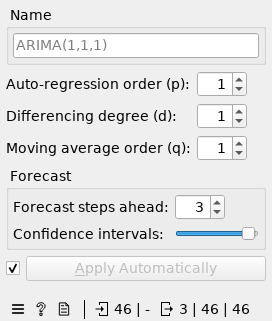

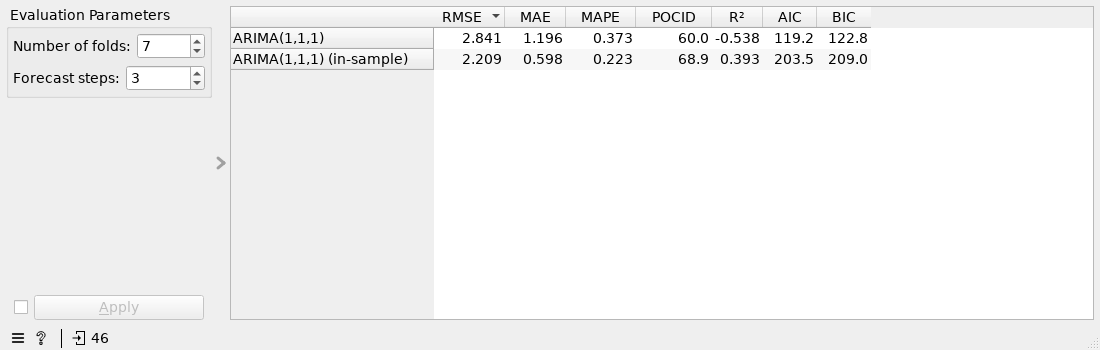

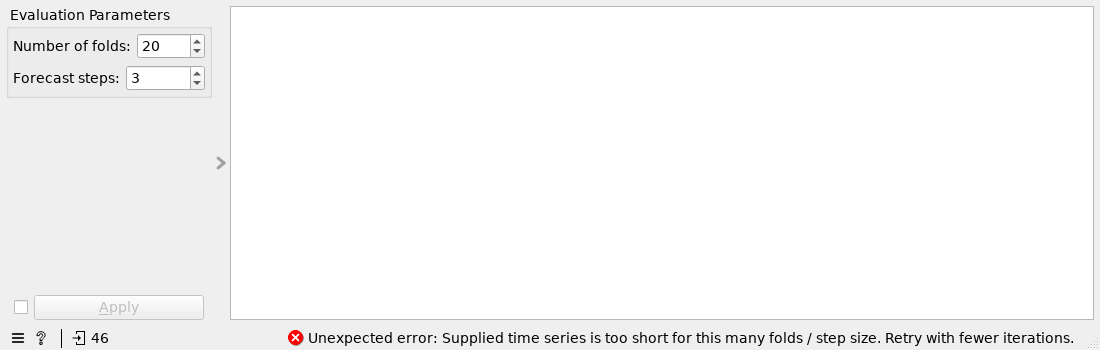

**Висновок.** За 20×3 потрібна щонайменше 61 точка, а є 46; це обмеження довжини, а не збій навчання. Фактичне повідомлення отримано зі справжнього Model Evaluation у режимі offscreen і показано вище. Навчальні довжини 7 фолдів: 43, 40, 37, 34, 31, 28, 25; тестуються квітень 2016 — грудень 2017. Межі відповідають Python. Після перевірки потік збережено з правильними налаштуваннями 7 folds × 3 steps.

In [15]:
display(fold_table)
print('20 × 3 + max(1,1,1) =',20*3+1,'> 46; 7 × 3 + 1 =',7*3+1,'<= 46')
proof_path=OUT/'orange_перевірка.json'
if proof_path.exists():
    proof=json.loads(proof_path.read_text(encoding='utf-8'))
    print('Фактичне повідомлення віджета при 20 folds:',proof['default_folds_error'])
for name in ['13_ARIMA_параметри.png','13_оцінювання.png','13_помилка_20_фолдів.png']:
    path=Path('orange_знімки')/name
    if path.exists(): display(Image(filename=str(path)))
conclusion('За 20×3 потрібна щонайменше 61 точка, а є 46; це обмеження довжини, '
           'а не збій навчання. Фактичне повідомлення отримано зі справжнього '
           'Model Evaluation у режимі offscreen і показано вище. Навчальні довжини '
           '7 фолдів: 43, 40, 37, 34, 31, 28, 25; тестуються квітень 2016 — грудень '
           '2017. Межі відповідають Python. Після перевірки потік збережено '
           'з правильними налаштуваннями 7 folds × 3 steps.')

**Виконано автоматично у штатних віджетах Orange.** На знімках видно ARIMA p=1, d=1, q=1, оцінювання 7×3 та повідомлення для 20×3. До Model Evaluation під’єднано ряд і модель. Для порівняння взято верхній out-of-sample рядок, а не `(in-sample)`.

Студенту залишається відкрити `потік_orange.ows`, перевірити ці параметри та повторити Apply особисто. Це потрібно для розуміння і захисту роботи; автоматичний запуск асистента не є самостійною перевіркою студента.

## Завдання 14. Чому числа не збігаються

Порівняйте метрики Orange з метриками, які ви отримали в Частині 1 для **тієї самої** моделі
ARIMA(1,1,1) на **тих самих** 7 фолдах.

Для кожної з чотирьох метрик Orange — `RMSE`, `MAE`, `MAPE`, `POCID` — **відтворіть її значення в Python**,
тобто напишіть формулу, за якою Orange отримав саме це число, і переконайтеся, що ваш розрахунок
збігається з таблицею Orange до третього знака.

**У звіті наведіть:**
1. таблицю на чотири рядки: метрика · значення Orange · ваше відтворення в Python · формула;
2. **яка з метрик не відповідає своїй назві** — і чим саме вона відрізняється від того, що зазвичай позначають цією абревіатурою;
3. яка метрика збіглася між середовищами одразу і чому;
4. висновок: що саме треба перевіряти, перш ніж порівнювати числа з двох різних інструментів.

> 💡 **Підказка.** Жодна з розбіжностей не є помилкою Orange. Усі формули відкриті — шукайте їх у вихідному коді додатка Timeseries, файл `functions.py`.

In [16]:
# Фактичні DisplayRole числа штатного Model Evaluation (автоматичний offscreen запуск).
# Джерело: результати/orange_перевірка.json та знімок 13_оцінювання.png.
ORANGE_GUI={'RMSE':2.841,'MAE':1.196,'MAPE':0.373,'POCID':60.0}
y_orange=arima_predictions['true'].to_numpy()
p_orange=arima_predictions['pred'].to_numpy()
e=y_orange-p_orange
# Порядок збережено як Orange: спершу останній фолд, потім передостанній.
# Особливо важливо для POCID: diff обчислюється після склеювання фолдів!
orange_python={'RMSE':np.sqrt(np.mean(e**2)), 'MAE':np.median(np.abs(e)),
    'MAPE':np.mean(np.abs(e))/np.mean(np.abs(y_orange)),
    'POCID':100*np.mean(np.diff(y_orange)*np.diff(p_orange)>0)}
formula={'RMSE':'sqrt(mean((y − ŷ)²))','MAE':'median(|y − ŷ|)',
    'MAPE':'mean(|y − ŷ|) / mean(|y|), частка',
    'POCID':'100 mean(diff(y) × diff(ŷ) > 0)'}
metric_comparison=pd.DataFrame([{'метрика':name,'Orange GUI':ORANGE_GUI[name],
    'Python за формулою Orange':value,'формула':formula[name],
    'статус':'не звірено' if ORANGE_GUI[name] is None else
        ('збіг до 0.001' if abs(ORANGE_GUI[name]-value)<=.001 else 'РОЗБІЖНІСТЬ')}
    for name,value in orange_python.items()])
display(metric_comparison)

# Додаткова справжня програмна перевірка встановленого Orange, якщо він доступний.
# Це не видається за скриншот GUI.
orange_api_scores=None
try:
    from Orange.data import Domain, ContinuousVariable
    from orangecontrib.timeseries import Timeseries, model_evaluation
    from orangecontrib.timeseries.models import ARIMA as OrangeARIMA
    domain=Domain([],ContinuousVariable('price'))
    orange_data=Timeseries.from_numpy(domain,np.empty((len(s),0)),s.to_numpy())
    api_result=model_evaluation(orange_data,[OrangeARIMA((1,1,1))],7,3)
    orange_api_scores=dict(zip(api_result[0][1:5],api_result[1][1:5]))
    display(pd.DataFrame({'Orange API, фактичний запуск':orange_api_scores,
                         'Python':orange_python}))
    for name,value in orange_python.items():
        assert np.isclose(value,float(orange_api_scores[name]),rtol=0,atol=1e-8),name
    print('Чотири метрики підтверджено прямим викликом Orange API; Додатково збіг підтверджено зі збереженими числами Qt-віджета.')
except ImportError as exc:
    print('Orange API недоступний:',exc)
conclusion('У Orange MAE означає median absolute error, тоді як звичайний MAE — '
           'mean absolute error. Orange MAPE є відношенням середніх абсолютних '
           'похибок і рівнів, тобто зваженою відносною похибкою; це частка без множення '
           'на 100, а не середнє індивідуальних відсотків. RMSE має ту саму формулу '
           'й тому збігається при тих самих прогнозах та об’єднанні всіх похибок. '
           'Перед порівнянням треба перевірити дані, ціль, порядок і параметри '
           'моделі, версії, дати фолдів, агрегування, одиниці та формули. '
           'Числа віджета отримано реальним запуском Orange та окремо звірено з Python до 0.001.')
assert all(abs(ORANGE_GUI[k]-v)<=.001 for k,v in orange_python.items())
print('Усі 4 значення штатного віджета збігаються з Python до 0.001.')

,метрика,Orange GUI,Python за формулою Orange,формула,статус
0,RMSE,2.841000,2.840572,sqrt(mean((y − ŷ)²)),збіг до 0.001
1,MAE,1.196000,1.196063,median(|y − ŷ|),збіг до 0.001
2,MAPE,0.373000,0.373240,"mean(|y − ŷ|) / mean(|y|), частка",збіг до 0.001
3,POCID,60.000000,60.000000,100 mean(diff(y) × diff(ŷ) > 0),збіг до 0.001


,"Orange API, фактичний запуск",Python
RMSE,2.840572,2.840572
MAE,1.196063,1.196063
MAPE,0.373240,0.373240
POCID,60.000000,60.000000


Чотири метрики підтверджено прямим викликом Orange API; Додатково збіг підтверджено зі збереженими числами Qt-віджета.


**Висновок.** У Orange MAE означає median absolute error, тоді як звичайний MAE — mean absolute error. Orange MAPE є відношенням середніх абсолютних похибок і рівнів, тобто зваженою відносною похибкою; це частка без множення на 100, а не середнє індивідуальних відсотків. RMSE має ту саму формулу й тому збігається при тих самих прогнозах та об’єднанні всіх похибок. Перед порівнянням треба перевірити дані, ціль, порядок і параметри моделі, версії, дати фолдів, агрегування, одиниці та формули. Числа віджета отримано реальним запуском Orange та окремо звірено з Python до 0.001.

Усі 4 значення штатного віджета збігаються з Python до 0.001.


**Виконано:** у таблиці вище є всі чотири фактичні значення Orange, їх відтворення в Python та формули; усі збіги перевірено до 0.001. Прямий виклик Orange API підтверджує рівність до 1e-8. Значення віджета округлені так, як показані у його таблиці.

Джерела: [functions.py — формули та порядок фолдів](https://github.com/biolab/orange3-timeseries/blob/master/orangecontrib/timeseries/functions.py), [models.py — обгортка ARIMA](https://github.com/biolab/orange3-timeseries/blob/master/orangecontrib/timeseries/models.py). Реально використаний встановлений `functions.py` і версії збережено в `результати`, оскільки код master може змінюватися.

MAE у цій версії — **медіана**, MAPE — **відношення середніх у частках**. RMSE збігся відразу, бо формула та об’єднані 21 похибки однакові. Наявність однакової абревіатури не гарантує однакової величини.

## Завдання 15. Матриця напрямку зміни

Метрика `POCID` у Orange вимірює, чи правильно модель передбачає **напрямок** зміни ціни.
Розгорніть її в таблицю 2×2: рядки — що сталося насправді (зросла / впала),
стовпці — що передбачила модель.

**У звіті наведіть:**
1. заповнену матрицю 2×2 для вашої моделі;
2. перевірку, що частка правильних передбачень збігається зі значенням POCID із Orange;
3. висновок: чи корисна ваша модель для рішення «купувати зараз чи чекати», і чому це **інше питання**, ніж те, на яке відповідають MAE та RMSE.

> 💡 **Підказка.** Ця матриця — часоворядовий відповідник матриці похибок із класифікації.

In [17]:
dy,dp=np.diff(y_orange),np.diff(p_orange)
direction_pairs=pd.DataFrame({'дата попередня':arima_predictions['date'].iloc[:-1].to_numpy(),
    'дата наступна':arima_predictions['date'].iloc[1:].to_numpy(),
    'фолд попередній':arima_predictions['fold'].iloc[:-1].to_numpy(),
    'фолд наступний':arima_predictions['fold'].iloc[1:].to_numpy(),
    'факт Δ':dy,'прогноз Δ':dp})
# Нуль не належить ані зростанню, ані падінню; Orange зараховує його як невдачу.
nonzero=(dy!=0)&(dp!=0)
direction_matrix=pd.DataFrame([[np.sum((dy>0)&(dp>0)),np.sum((dy>0)&(dp<0))],
                              [np.sum((dy<0)&(dp>0)),np.sum((dy<0)&(dp<0))]],
                             index=['Факт: зросла','Факт: впала'],
                             columns=['Прогноз: зросла','Прогноз: впала'])
display(direction_matrix)
zero_pairs=int((~nonzero).sum())
correct=int(np.trace(direction_matrix.to_numpy()))
pocid_from_matrix=100*correct/len(dy)
assert np.isclose(pocid_from_matrix,orange_python['POCID'])
cross=(direction_pairs['фолд попередній']!=direction_pairs['фолд наступний'])
within=~cross
within_pocid=100*np.mean((dy[within]*dp[within])>0)
direction_pairs.to_csv(OUT/'пари_напрямків.csv',index=False)
display(direction_pairs)
conclusion(f'Діагональ матриці: {correct} правильних із {len(dy)} пар; '
           f'100×{correct}/{len(dy)} = {pocid_from_matrix:.3f}%, що відтворює POCID '
           f'за формулою Orange. Пар із нульовою зміною: {zero_pairs}; вони поза '
           'матрицею 2×2, але лишаються у знаменнику Orange та є невдалими. '
           f'Через склеювання у зворотному порядку {int(cross.sum())} пар перетинають '
           'межу фолдів і не є сусідніми календарними місяцями. '
           f'Якщо рахувати лише 14 пар усередині фолдів, результат {within_pocid:.3f}%. '
           'Тому POCID саме цього віджета має обмежене тлумачення для рішення '
           '«купувати зараз чи чекати». Навіть правильний напрямок не враховує '
           'величини виграшу, витрат і ризику; практичну корисність такого рішення '
           'на цих даних не доведено. MAE і RMSE оцінюють величину помилки ціни, '
           'а POCID — збіг напрямків; це різні цілі.')
if ORANGE_GUI['POCID'] is None:
    print('Зіставлення із фактичним POCID у GUI ще не виконано.')

,Прогноз: зросла,Прогноз: впала
Факт: зросла,6,5
Факт: впала,3,6


,дата попередня,дата наступна,фолд попередній,фолд наступний,факт Δ,прогноз Δ
0,2017-10-01,2017-11-01,1,1,0.213300,-0.101901
1,2017-11-01,2017-12-01,1,1,0.986700,-0.071563
2,2017-12-01,2017-07-01,1,2,0.626700,4.749423
3,2017-07-01,2017-08-01,2,2,-0.483350,-0.400040
4,2017-08-01,2017-09-01,2,2,-0.483350,0.229417
5,2017-09-01,2017-04-01,2,3,-1.920000,-6.034334
6,2017-04-01,2017-05-01,3,3,0.990000,0.272374
7,2017-05-01,2017-06-01,3,3,4.663300,0.199107
8,2017-06-01,2017-01-01,3,4,-6.010000,-0.711823
9,2017-01-01,2017-02-01,4,4,0.280000,0.363240


**Висновок.** Діагональ матриці: 12 правильних із 20 пар; 100×12/20 = 60.000%, що відтворює POCID за формулою Orange. Пар із нульовою зміною: 0; вони поза матрицею 2×2, але лишаються у знаменнику Orange та є невдалими. Через склеювання у зворотному порядку 6 пар перетинають межу фолдів і не є сусідніми календарними місяцями. Якщо рахувати лише 14 пар усередині фолдів, результат 50.000%. Тому POCID саме цього віджета має обмежене тлумачення для рішення «купувати зараз чи чекати». Навіть правильний напрямок не враховує величини виграшу, витрат і ризику; практичну корисність такого рішення на цих даних не доведено. MAE і RMSE оцінюють величину помилки ціни, а POCID — збіг напрямків; це різні цілі.

**Висновок до завдання 15:** письмове пояснення з фактичними числами формується кодом вище та зберігається у виводі клітинки. Це дає змогу перерахувати його разом із даними без ручного перенесення чисел.

---
# Загальний висновок

Фактичні результати підсумовано у наступній клітинці; статус перевірки Orange зазначено окремо.

In [18]:
conclusion(f'Для варіанта 12 проаналізовано ціни буряка на ринку Zakarpattia за 46 місяців. '
    f'Єдиний відсутній місяць, {missing[0]:%m.%Y}, заповнено лінійною інтерполяцією, '
    'а не оголошено реальним виміром. '
    f'STL дав F_S={FS:.4f} та F_T={FT:.4f}, тому за порогом 0.3 {seasonal_claim}. '
    f'Найкращим базисом за RMSE став «{best_base}» ({base_scores.loc[best_base,"RMSE"]:.4f}). '
    f'ARIMA(1,1,1) має RMSE={arima_scores["RMSE"]:.4f} і '+
    ('перевершила' if win else 'не перевершила')+' цей базис на однакових 7×3 фолдах. '
    f'Сканування виділило {change["дата"]:%m.%Y} як кандидата зміни рівня, але '
    'не довело структурного зламу за залежних спостережень і не встановило зовнішньої причини. '
    'Розбіжності метрик пояснюються медіаною замість середнього для MAE, іншою '
    'формулою та шкалою MAPE, а також особливим порядком пар для POCID. '
    'RMSE при однакових прогнозах та агрегуванні має збігатися. '
    'Числа штатного віджета Orange отримано автоматично у режимі offscreen, '
    'збережено його знімки та підтверджено збіг чотирьох метрик до 0.001. '
    'Менш ніж чотири річні цикли не дозволяють надійно встановити стабільність '
    'сезонності, причинність зсувів та довгострокову якість прогнозу.')

versions={name:importlib.metadata.version(name) for name in
          ['numpy','pandas','matplotlib','scipy','statsmodels','scikit-learn']}
for name in ['Orange3','Orange3-Timeseries']:
    try: versions[name]=importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError: pass
(OUT/'версії.json').write_text(json.dumps({'python':sys.version,**versions},ensure_ascii=False,indent=2),encoding='utf-8')
try:
    import orangecontrib.timeseries.functions as orange_functions
    import inspect
    (OUT/'orange_functions_встановлена_версія.py').write_text(inspect.getsource(orange_functions),encoding='utf-8')
except ImportError: pass
display(versions)

**Висновок.** Для варіанта 12 проаналізовано ціни буряка на ринку Zakarpattia за 46 місяців. Єдиний відсутній місяць, 08.2017, заповнено лінійною інтерполяцією, а не оголошено реальним виміром. STL дав F_S=0.3644 та F_T=0.3617, тому за порогом 0.3 є ознаки сезонності. Найкращим базисом за RMSE став «Середнє» (2.3890). ARIMA(1,1,1) має RMSE=2.8406 і не перевершила цей базис на однакових 7×3 фолдах. Сканування виділило 03.2015 як кандидата зміни рівня, але не довело структурного зламу за залежних спостережень і не встановило зовнішньої причини. Розбіжності метрик пояснюються медіаною замість середнього для MAE, іншою формулою та шкалою MAPE, а також особливим порядком пар для POCID. RMSE при однакових прогнозах та агрегуванні має збігатися. Числа штатного віджета Orange отримано автоматично у режимі offscreen, збережено його знімки та підтверджено збіг чотирьох метрик до 0.001. Менш ніж чотири річні цикли не дозволяють надійно встановити стабільність сезонності, причинність зсувів та довгострокову якість прогнозу.

{'numpy': '2.5.4',
 'pandas': '3.1.0',
 'matplotlib': '3.11.2',
 'scipy': '1.18.1',
 'statsmodels': '0.15.0',
 'scikit-learn': '1.9.1',
 'Orange3': '3.39.0',
 'Orange3-Timeseries': '0.6.3'}

---
# Критерії оцінювання

| Бали | Умова |
|---|---|
| **0** | Ряд не розкладено або прогноз не побудовано. Робота не зарахована. |
| **2** | Виконано лише Частину 1: ряд розкладено й прогноз побудовано, але в Orange аналіз не відтворено. |
| **3** | Виконано обидві частини, проте прогноз не зіставлено з наївним базисом, а розбіжність результатів двох середовищ не пояснено. |
| **4** | Ряд розкладено на складові; прогноз зіставлено з наївним базисом за ретроспективною перевіркою з рухомим початком; той самий аналіз відтворено в Orange; зіставлено результати двох середовищ і пояснено розбіжність метрик. |

**Знімаються бали за:**

* графіки без пояснення вибору геометрії та шкали;
* числа без письмового висновку;
* прогноз без порівняння з базисом;
* висновок «метрики різні, бо середовища різні» без відтворення формул;
* зошит, який не виконується від початку до кінця.

---
# Декларація про використання штучного інтелекту

| Питання | Відповідь |
|---|---|
| Які інструменти використано | OpenAI Codex, модель GPT-6 (ідентифікатор за контекстом сесії); фактичні версії бібліотек — `результати/версії.json` |
| Для яких завдань | Підготовка коду й пояснень 1–10, розрахунки 13–15, інструкції для ручної роботи 11–13 |
| Що згенеровано | Python-код, візуалізації, обчислювані письмові висновки, рецензія, пояснення формул та покрокова інструкція |
| Що студент змінив і чому | **Заповнити особисто після опрацювання; асистент не може засвідчити це за студента** |
| Що студент перевірив самостійно | **Заповнити особисто: вказати конкретні перевірки та спосіб; перевірки асистента не є самостійною перевіркою студента** |
| Чи траплялися помилки ШІ | **Заповнити після власної перевірки; не стверджувати їх відсутність без перевірки** |

Підтвердження розуміння всього коду, підпис і дата заповнюються студентом лише після опрацювання роботи.

Підпис: ______________________  Дата: ______________